# Synthetic persistence experiment: mean-defined regimes

Compare Gaussian and three-component GMM HMMs with mean-defined regimes and self-transition probability 0.995, matching the volatility experiment.


## Setup and experiment settings

Use four families (Gaussian, Student-t, standardized trimodal, and shifted Gamma), 10 replicates, 10 starts, 20,000 training observations, 5,000 independent test observations, and at most 1,000 EM updates per start.

The helper is loaded under a private module name so this experiment does not change the original helper’s 0.90 persistence. Outputs are saved under `data/synthetic/gmm_synthetic_experiments`

In [1]:
from pathlib import Path
import sys
import importlib.util
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

project_root = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "src/synthetic_data_generation/markov_process_generation.py").exists())
for path in (project_root / "src", project_root / "notebooks"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

# Load an independent module instance; leave the original experiment unchanged.
persistence_spec = importlib.util.spec_from_file_location(
    "synthetic_persistence_reference",
    project_root / "notebooks/synthetic_emission_comparison.py",
)
persistence_reference = importlib.util.module_from_spec(persistence_spec)
sys.modules[persistence_spec.name] = persistence_reference
persistence_spec.loader.exec_module(persistence_reference)
persistence_reference.TRANSITIONS = np.full((3, 3), 0.0025)
np.fill_diagonal(persistence_reference.TRANSITIONS, 0.995)

from synthetic_persistence_reference import (
    ExperimentConfig, STATES, INITIAL, TRANSITIONS, MODEL_NAMES, MODEL_COLORS,
    MODEL_STYLES, WIDE_FAMILY, SUMMARY_METRICS, PAIR_KEYS,
    true_moments, true_log_density, mixture_parameters, generate_datasets,
    run_experiment, paired_results, paired_differences, emission_kl,
    plot_learning_curves, plot_confusions, save_artifacts,
)

CONFIG = ExperimentConfig(
    master_seed=42,
    train_sizes=(20_000,),
    n_test=5_000,
    n_density=10_000,
    n_replicates=10,
    n_starts=10,
    n_components=3,         # Components within each state, not extra Markov states.
    max_iter=1000,
    tol_per_observation=1e-6,
    min_variance=1e-6,
    include_wide=False,     # Use only the four moment-matched families.
    bootstrap_samples=2_000,
)

plt.rcParams.update({"font.size": 10, "figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": .18, "axes.spines.top": False, "axes.spines.right": False})
STATE_COLORS = ["#4477AA", "#CC6677", "#228833"]
attempt_count = len(CONFIG.families) * len(CONFIG.train_sizes) * CONFIG.n_replicates * CONFIG.n_starts * 2
print(f"{len(CONFIG.families)} families × {len(CONFIG.train_sizes)} sizes × "
      f"{CONFIG.n_replicates} replicates × {CONFIG.n_starts} starts × 2 models = {attempt_count:,} attempted fits")
display(pd.DataFrame([
    {"family": family, "state": int(k), "true_mean": true_moments(family)[0][k],
     "true_variance": true_moments(family)[1][k]}
    for family in CONFIG.families for k in STATES
]).round(4))

4 families × 1 sizes × 10 replicates × 10 starts × 2 models = 800 attempted fits


,family,state,true_mean,true_variance
0,Gaussian,0,-2.0,1.0
1,Gaussian,1,0.0,1.0
2,Gaussian,2,2.0,1.0
3,Student-t,0,-2.0,1.0
4,Student-t,1,0.0,1.0
5,Student-t,2,2.0,1.0
6,Trimodal,0,-2.0,1.0
7,Trimodal,1,0.0,1.0
8,Trimodal,2,2.0,1.0
9,Skewed Gamma,0,-2.0,1.0


### Design and interpretation

Both HMMs have $K=3$ hidden states. In the GMM model, each state emits from a mixture of $M=3$ Gaussians by default:

$$
p(x_t\mid z_t=k)=\sum_{m=1}^{M}w_{km}\,\mathcal{N}(x_t;\mu_{km},\sigma_{km}^2).
$$

The mixture component is independently drawn conditional on the state; Gaussian, Student-t ($\nu=2.5$), standardized trimodal, and shifted Gamma (shape 4) emissions share means $(-2,0,2)$ and variance 1.

$$
A=\begin{pmatrix}.995&.0025&.0025\\.0025&.995&.0025\\.0025&.0025&.995\end{pmatrix},\qquad \pi=(1/3,1/3,1/3).
$$

Expected regime duration is $1/(1-0.995)=200$ observations, with random durations and no forced minimum.

## Generate shared data and inspect coverage

Generate new latent paths with self-transition probability 0.995. Families share paths within each replicate.


In [2]:
datasets, coverage = generate_datasets(CONFIG)
np.testing.assert_allclose(INITIAL @ TRANSITIONS, INITIAL)
for family in CONFIG.families:
    if family in ("Trimodal", WIDE_FAMILY):
        weights, centers, stds = mixture_parameters(family)
        actual_means = np.sum(weights * centers, axis=1)
        actual_variances = np.sum(weights * (stds**2 + (centers - actual_means[:, None])**2), axis=1)
        np.testing.assert_allclose(actual_means, true_moments(family)[0], atol=1e-12)
        np.testing.assert_allclose(actual_variances, true_moments(family)[1], atol=1e-12)
    for replicate in range(CONFIG.n_replicates):
        for split in ("train", "test"):
            np.testing.assert_array_equal(datasets[replicate, family][split].state,
                                          datasets[replicate, "Gaussian"][split].state)
print(f"Generated {len(datasets)} family/replicate datasets; confirmed shared latent paths.")
display(coverage[(coverage.family == "Gaussian") & (coverage.replicate == 0)])
display(datasets[0, "Trimodal"]["train"].head())

Generated 40 family/replicate datasets; confirmed shared latent paths.


,family,replicate,split,n,state_visits,transition_counts,switches
0,Gaussian,0,train,20000,"[5139, 7266, 7595]","[[5102, 13, 24], [15, 7233, 17], [22, 20, 7553]]",111
1,Gaussian,0,test,5000,"[2658, 1726, 616]","[[2650, 4, 3], [5, 1719, 2], [3, 2, 611]]",19


,time,state,component,x
0,0,2,1,2.287336
1,1,2,0,0.853907
2,2,2,1,1.914327
3,3,2,0,0.875296
4,4,2,1,2.186129


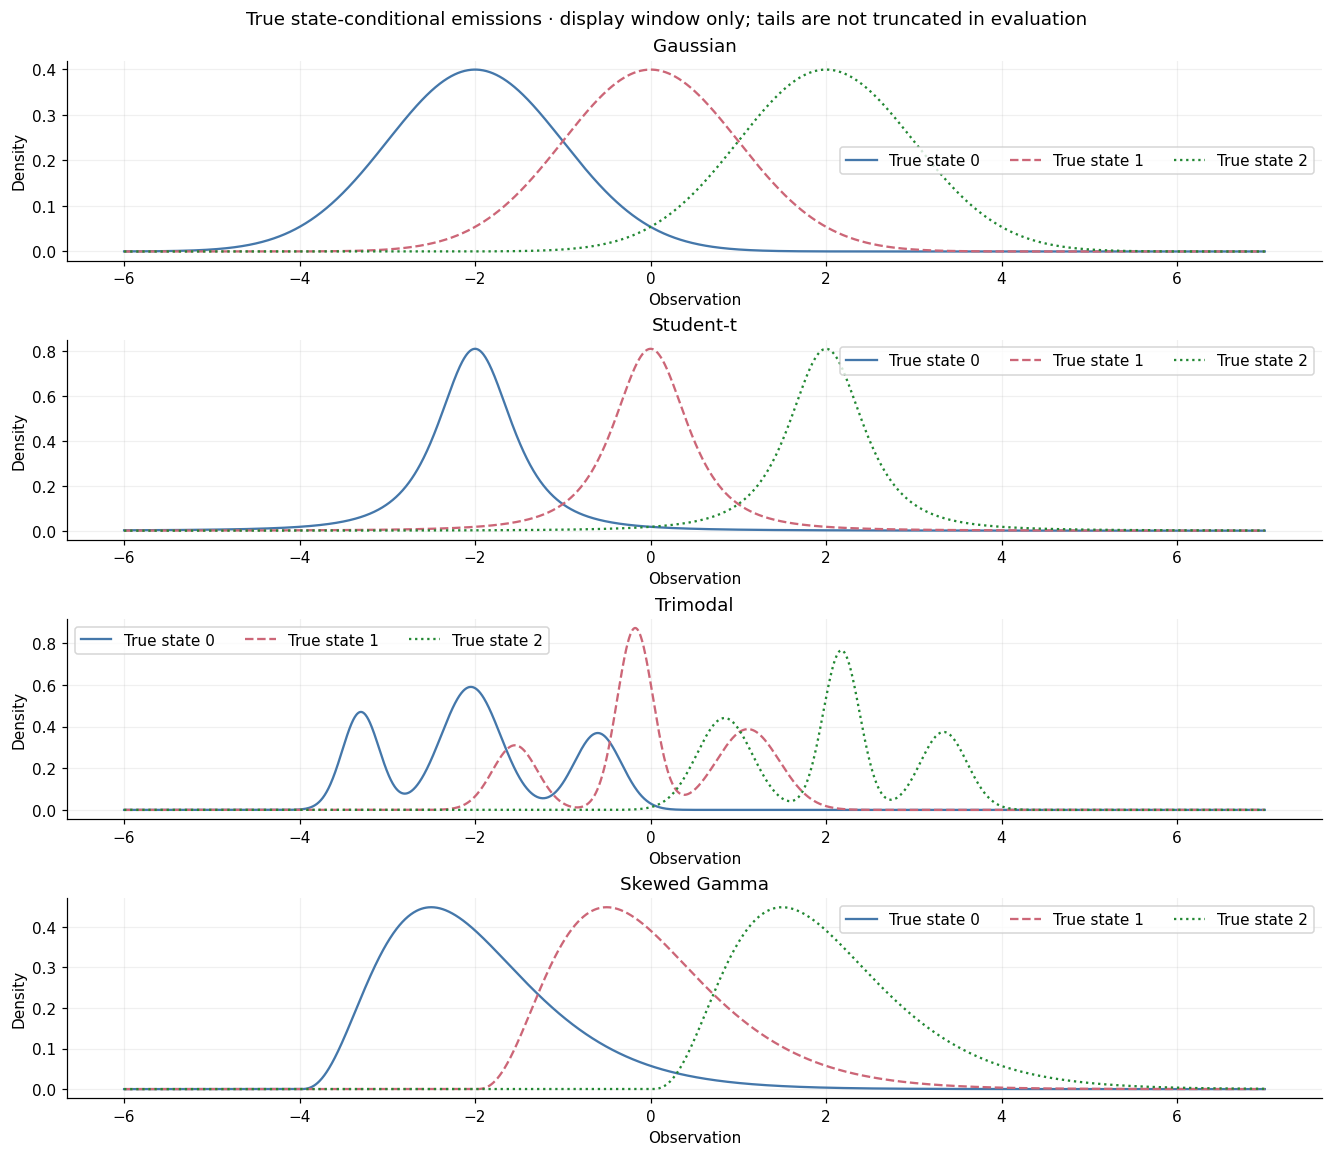

In [3]:
fig, axes = plt.subplots(len(CONFIG.families), 1, figsize=(12, 2.6 * len(CONFIG.families)),
                         squeeze=False, layout="constrained")
for ax, family in zip(axes.flat, CONFIG.families):
    grid = np.linspace(-17, 20, 3_000) if family == WIDE_FAMILY else np.linspace(-6, 7, 2_400)
    for k in STATES:
        ax.plot(grid, np.exp(true_log_density(family, k, grid)), color=STATE_COLORS[k],
                linestyle=["-", "--", ":"][k], label=f"True state {k}")
    ax.set(title=family, xlabel="Observation", ylabel="Density")
    ax.legend(ncol=3)
fig.suptitle("True state-conditional emissions · display window only; tails are not truncated in evaluation")
plt.show()

## Fit both models, evaluate, and save raw artifacts

In [4]:
run = run_experiment(CONFIG, datasets)
run_dir = save_artifacts(project_root, CONFIG, datasets, coverage, run)
results, attempts = run["results"], run["attempts"]
assert len(attempts) == attempt_count
assert len(results) == attempt_count // CONFIG.n_starts
print(f"Saved raw artifacts to {run_dir}")

def show_and_save(fig, name):
    fig.savefig(run_dir / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

import shutil

shutil.copy2(
    project_root / "notebooks/synthetic_persistence_experiment.ipynb",
    run_dir / "synthetic_persistence_experiment.ipynb",
)


Gaussian | N=20,000 | rep=00 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=00 | GMM HMM: ok, converged=True
Gaussian | N=20,000 | rep=01 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=01 | GMM HMM: ok, converged=True
Gaussian | N=20,000 | rep=02 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=02 | GMM HMM: ok, converged=True
Gaussian | N=20,000 | rep=03 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=03 | GMM HMM: ok, converged=True
Gaussian | N=20,000 | rep=04 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=04 | GMM HMM: ok, converged=True
Gaussian | N=20,000 | rep=05 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=05 | GMM HMM: ok, converged=True
Gaussian | N=20,000 | rep=06 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=06 | GMM HMM: ok, converged=True
Gaussian | N=20,000 | rep=07 | Gaussian HMM: ok, converged=True
Gaussian | N=20,000 | rep=07 | GMM HMM: ok, converged=True
Gaussian | N=20,

PosixPath('/Users/leoyang/Desktop/School/CSCD94/data/synthetic/gmm_synthetic_experiments/20261024T212804Z-4r1by0vo/synthetic_persistence_experiment.ipynb')

## Metrics and comparison population

All classification metrics score the **aligned test Viterbi states**. Values lie in $[0,1]$ except MCC and ARI, which can be negative.

| Metric | Interpretation |
|---|---|
| Precision / recall / F1 per state | False-positive control / state coverage / their harmonic mean |
| Macro precision / recall / F1 | Equal weight for each of the three true states; primary classification comparison |
| Weighted precision / recall / F1 | Weighted by true test-state support; common states contribute more |
| Balanced accuracy | Mean per-state recall; equals macro recall here |
| Accuracy / MCC / ARI / NMI | Overall hard-label recovery; MCC adjusts for marginal counts; ARI and NMI ignore label permutations |
| Switch precision / recall / F1 | Whether $z_t\ne z_{t-1}$ occurs at the exact correct time; no tolerance window |
| State log loss / Brier score | Quality of aligned smoothed posterior probabilities; lower is better |
| Test NLL per observation | Held-out sequence negative log likelihood per point, in nats; lower is better; compare models **within** a family |
| Emission KL | Equal-state mean of $D_{KL}(p_{true}\Vert p_{fit})$; lower is better |
| Transition / mean / variance RMSE | Recovery of transition probabilities and full state-emission moments; lower is better |
| Fit time / total fit time | Selected start / all starts for that model and replicate, excluding evaluation and plots |

Undefined precision/F1 (no predictions for a state) and undefined switch scores use `zero_division=0`. State log loss uses the reference's float64-epsilon floor; capped and stored-zero fractions are reported. Brier is the mean **sum over states** of squared probability errors, with range $[0,2]$.

For GMM moment recovery, use the whole mixture:

$$
\bar\mu_k=\sum_m w_{km}\mu_{km},\qquad
\operatorname{Var}(X\mid k)=\sum_m w_{km}\left[\sigma_{km}^2+(\mu_{km}-\bar\mu_k)^2\right].
$$

Mixture components are not individually aligned because their order is arbitrary. Quadrature integrates each true mixture component in its standardized coordinate to resolve narrow, separated modes.

In [20]:
paired = paired_results(results)
expected_groups = pd.MultiIndex.from_product(
    [CONFIG.families, CONFIG.train_sizes, MODEL_NAMES], names=["family", "n_train", "model"])
coverage_summary = results.assign(success=results.evaluation_status.eq("ok")).groupby(
    ["family", "n_train", "model"]).agg(evaluations=("success", "size"), successful=("success", "sum"))
coverage_summary = coverage_summary.reindex(expected_groups)
paired_counts = paired.groupby(["family", "n_train", "model"]).size().rename("complete_pairs")
coverage_summary = coverage_summary.join(paired_counts).fillna({"complete_pairs": 0})
display(coverage_summary.astype(int))
coverage_summary.to_csv(run_dir / "comparison_coverage.csv")
if paired.empty:
    raise RuntimeError(f"No successful model pairs. Inspect results/attempts in {run_dir} before plotting.")

summary = paired.groupby(["family", "n_train", "model"])[SUMMARY_METRICS].agg(["mean", "std", "count"])
summary.to_csv(run_dir / "paired_metric_summary.csv")
display(paired.groupby(["family", "n_train", "model"])[[
    "aligned_accuracy", "precision_macro", "recall_macro", "f1_macro",
    "balanced_accuracy", "mcc", "f1_weighted", "test_nll", "emission_kl"
]].mean().round(4))

evaluations  successful  complete_pairs
family       n_train model                                                
Gaussian     20000   Gaussian HMM           10          10              10
                     GMM HMM                10          10              10
Student-t    20000   Gaussian HMM           10          10              10
                     GMM HMM                10          10              10
Trimodal     20000   Gaussian HMM           10          10              10
                     GMM HMM                10          10              10
Skewed Gamma 20000   Gaussian HMM           10          10              10
                     GMM HMM                10          10              10

aligned_accuracy  precision_macro  \
family       n_train model                                             
Gaussian     20000   GMM HMM                 0.9980           0.9980   
                     Gaussian HMM            0.9980           0.9980   
Skewed Gamma 20000   GMM HMM                 0.9985           0.9983   
                     Gaussian HMM            0.9973           0.9969   
Student-t    20000   GMM HMM                 0.9992           0.9991   
                     Gaussian HMM            0.9907           0.9902   
Trimodal     20000   GMM HMM                 0.9985           0.9985   
                     Gaussian HMM            0.9976           0.9974   

                                   recall_macro  f1_macro  balanced_accuracy  \
family       n_train model                                                     
Gaussian     20000   GMM HMM             0.9979    0.9979             0.9979   
                     Gaussian HMM        0.9979    0.9980             0.9979   
Skewed Gamma 20000   GMM HMM             0.9985    0.9984             0.9985   
                     Gaussian HMM        0.9973    0.9971             0.9973   
Student-t    20000   GMM HMM             0.9992    0.9991             0.9992   
                     Gaussian HMM        0.9901    0.9901             0.9901   
Trimodal     20000   GMM HMM             0.9983    0.9984             0.9983   
                     Gaussian HMM        0.9976    0.9975             0.9976   

                                      mcc  f1_weighted  test_nll  emission_kl  
family       n_train model                                                     
Gaussian     20000   GMM HMM       0.9969       0.9980    1.4574       0.0004  
                     Gaussian HMM  0.9969       0.9980    1.4571       0.0002  
Skewed Gamma 20000   GMM HMM       0.9977       0.9985    1.3692       0.0068  
                     Gaussian HMM  0.9959       0.9973    1.4525       0.0890  
Student-t    20000   GMM HMM       0.9987       0.9992    1.0808       0.0105  
                     Gaussian HMM  0.9857       0.9907    1.3570       0.4928  
Trimodal     20000   GMM HMM       0.9977       0.9985    1.1622       0.0005  
                     Gaussian HMM  0.9962       0.9976    1.4506       0.2947

### Classification learning curves

Curves use the same successful replicate pairs for both models. Error bars show one sample standard deviation across replicates. Training sizes within a replicate reuse observations and therefore are correlated.

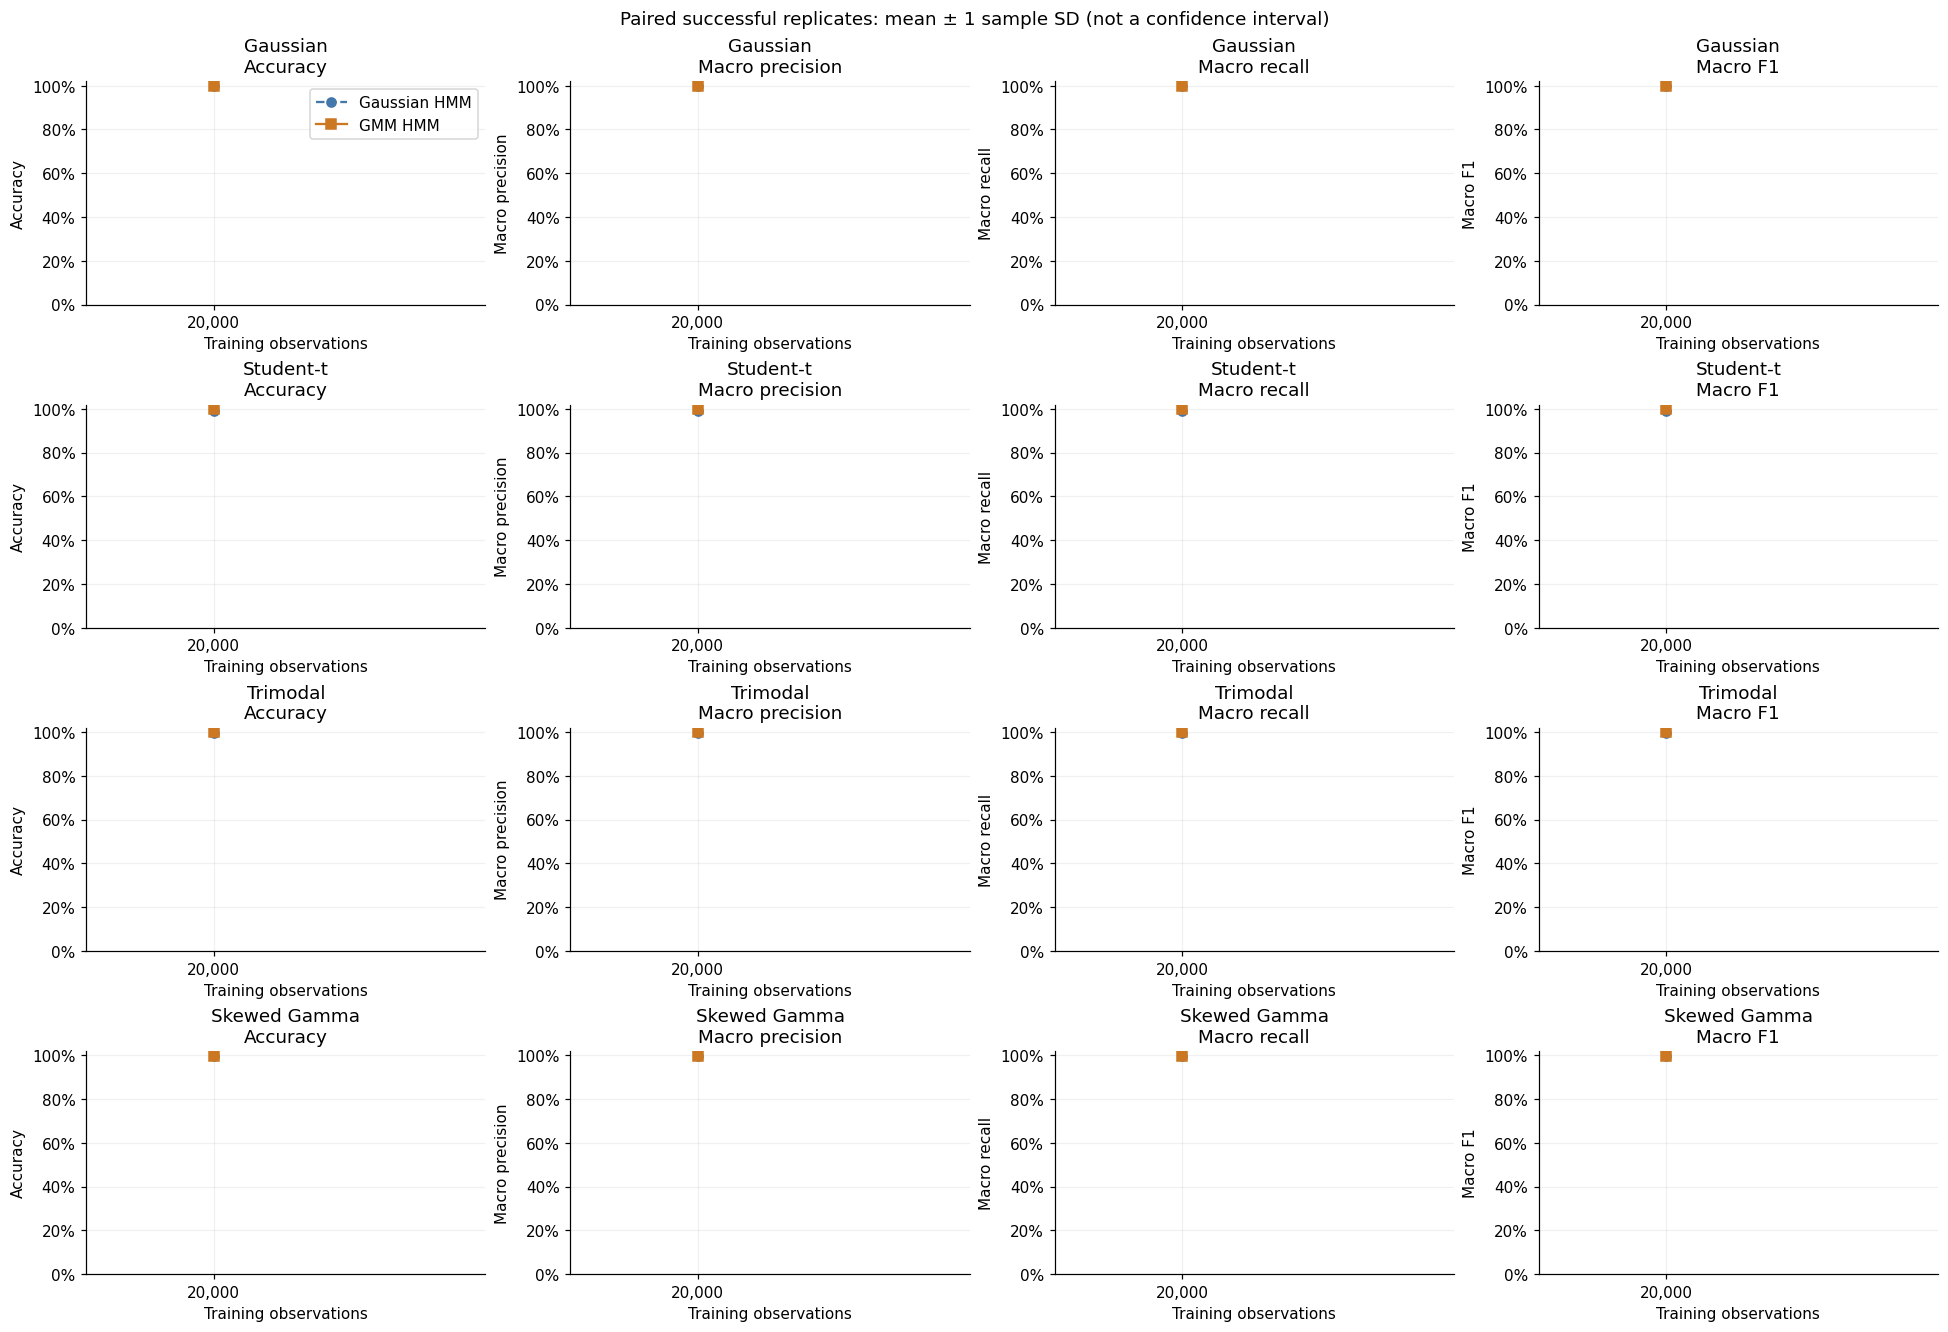

In [6]:
fig = plot_learning_curves(CONFIG, paired, [
    ("aligned_accuracy", "Accuracy", True),
    ("precision_macro", "Macro precision", True),
    ("recall_macro", "Macro recall", True),
    ("f1_macro", "Macro F1", True),
])
show_and_save(fig, "classification_learning_curves")

### Density, probability, and transition recovery

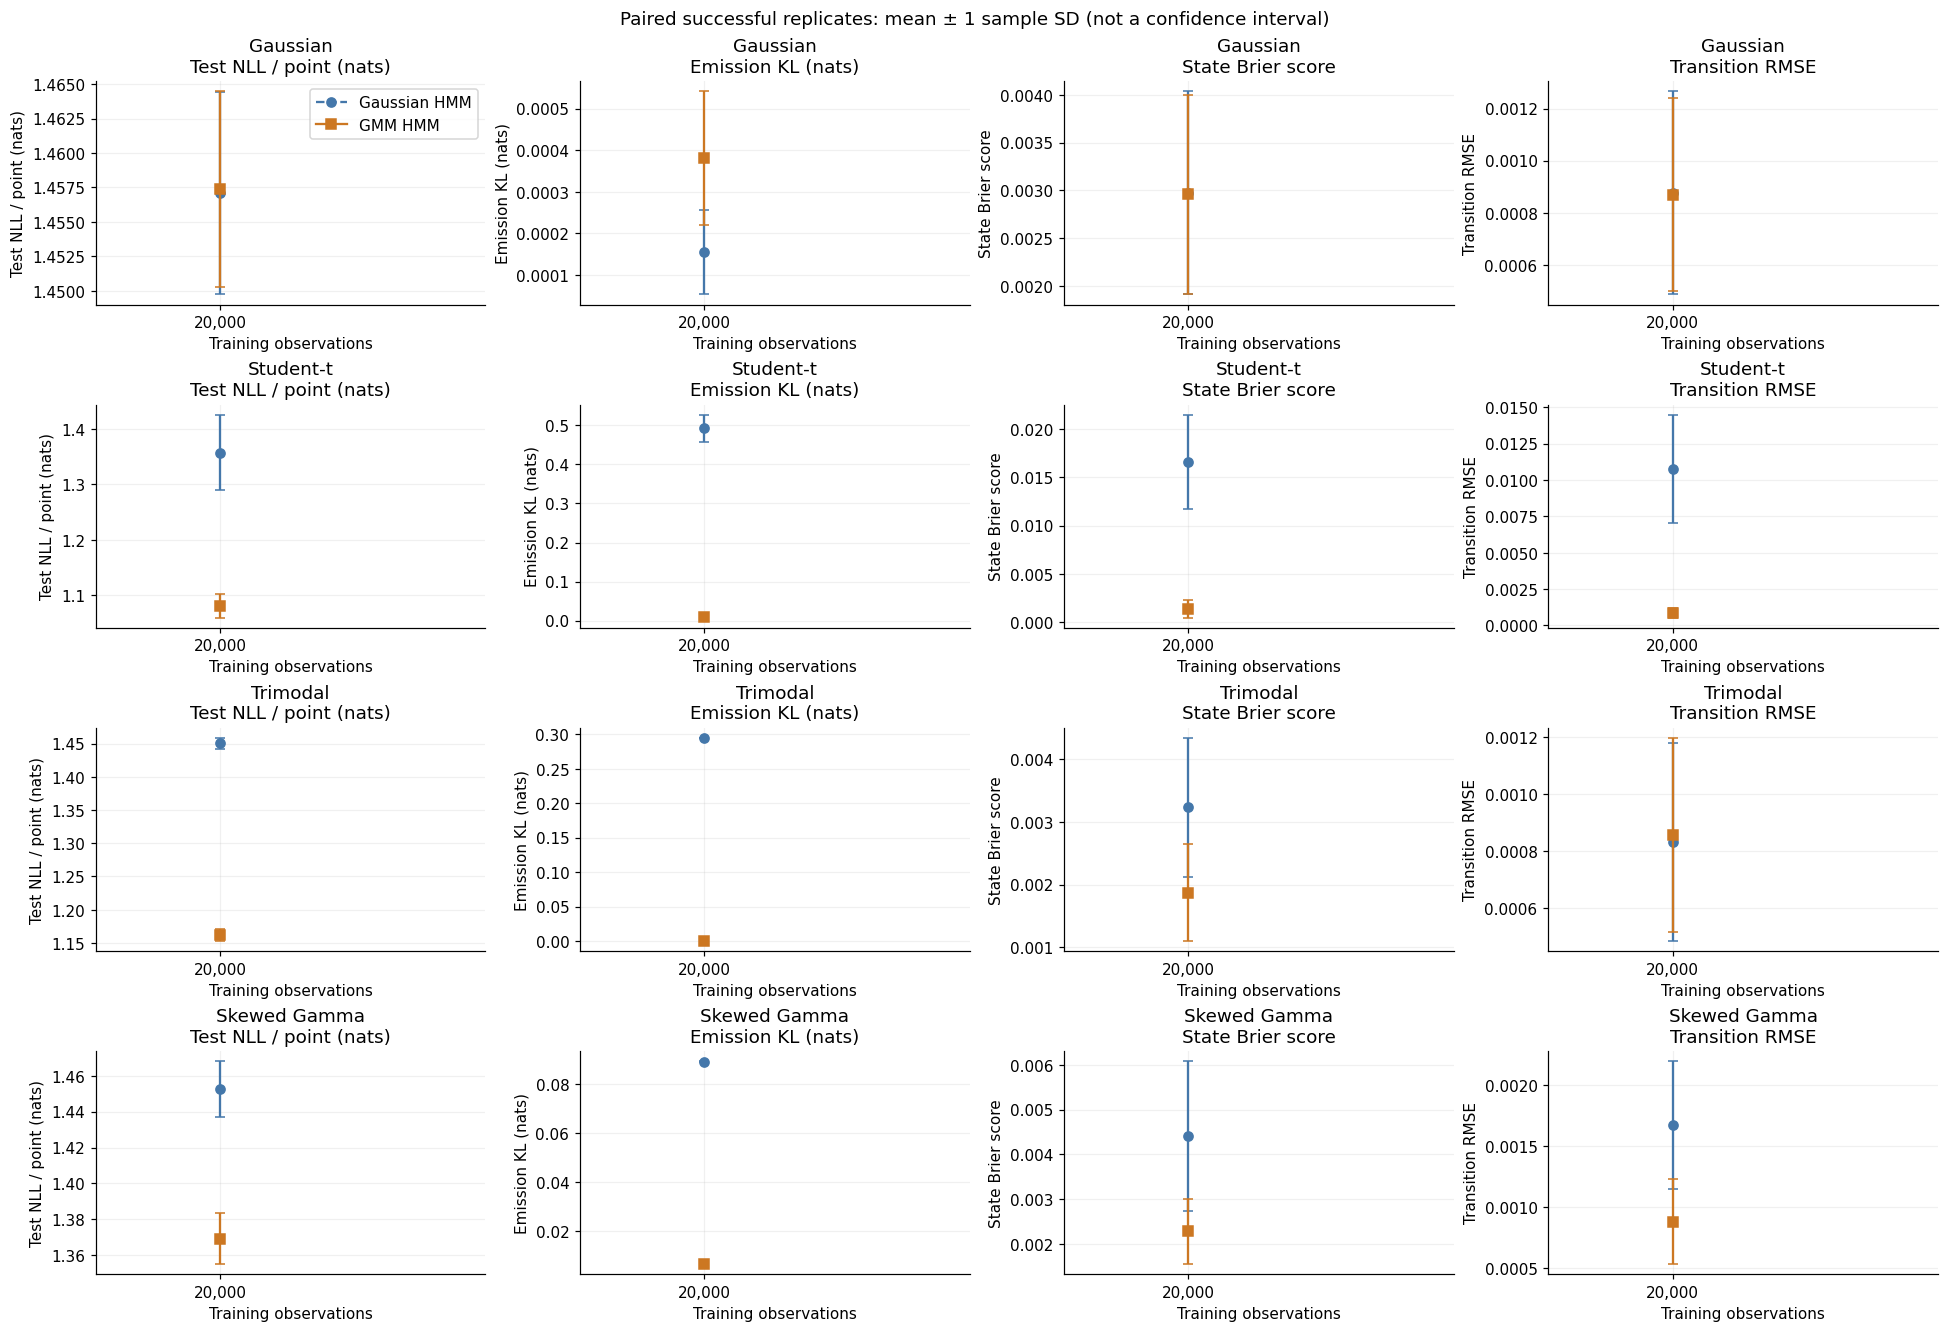

In [7]:
fig = plot_learning_curves(CONFIG, paired, [
    ("test_nll", "Test NLL / point (nats)", False),
    ("emission_kl", "Emission KL (nats)", False),
    ("state_brier_score", "State Brier score", False),
    ("transition_rmse", "Transition RMSE", False),
])
show_and_save(fig, "recovery_learning_curves")

### Paired GMM minus Gaussian differences

Compute differences within each replicate before averaging. Intervals are 95% percentile bootstrap intervals for the mean paired difference, resampling independent replicates (2,000 draws by default). The table includes every training size. The figure uses the largest size.

,family,n_train,metric,n_pairs,mean_delta,ci_low,ci_high
0,Gaussian,20000,f1_macro,10,-0.00002,-0.00012,0.00005
1,Gaussian,20000,test_nll,10,0.00029,0.00004,0.00061
2,Gaussian,20000,emission_kl,10,0.00023,0.00015,0.00030
3,Gaussian,20000,total_fit_seconds,10,90.18523,70.85090,114.49500
4,Skewed Gamma,20000,f1_macro,10,0.00125,0.00084,0.00175
5,Skewed Gamma,20000,test_nll,10,-0.08331,-0.08570,-0.08100
6,Skewed Gamma,20000,emission_kl,10,-0.08226,-0.08244,-0.08208
7,Skewed Gamma,20000,total_fit_seconds,10,375.27019,353.22861,396.61496
8,Student-t,20000,f1_macro,10,0.00901,0.00711,0.01093
9,Student-t,20000,test_nll,10,-0.27622,-0.31378,-0.23800


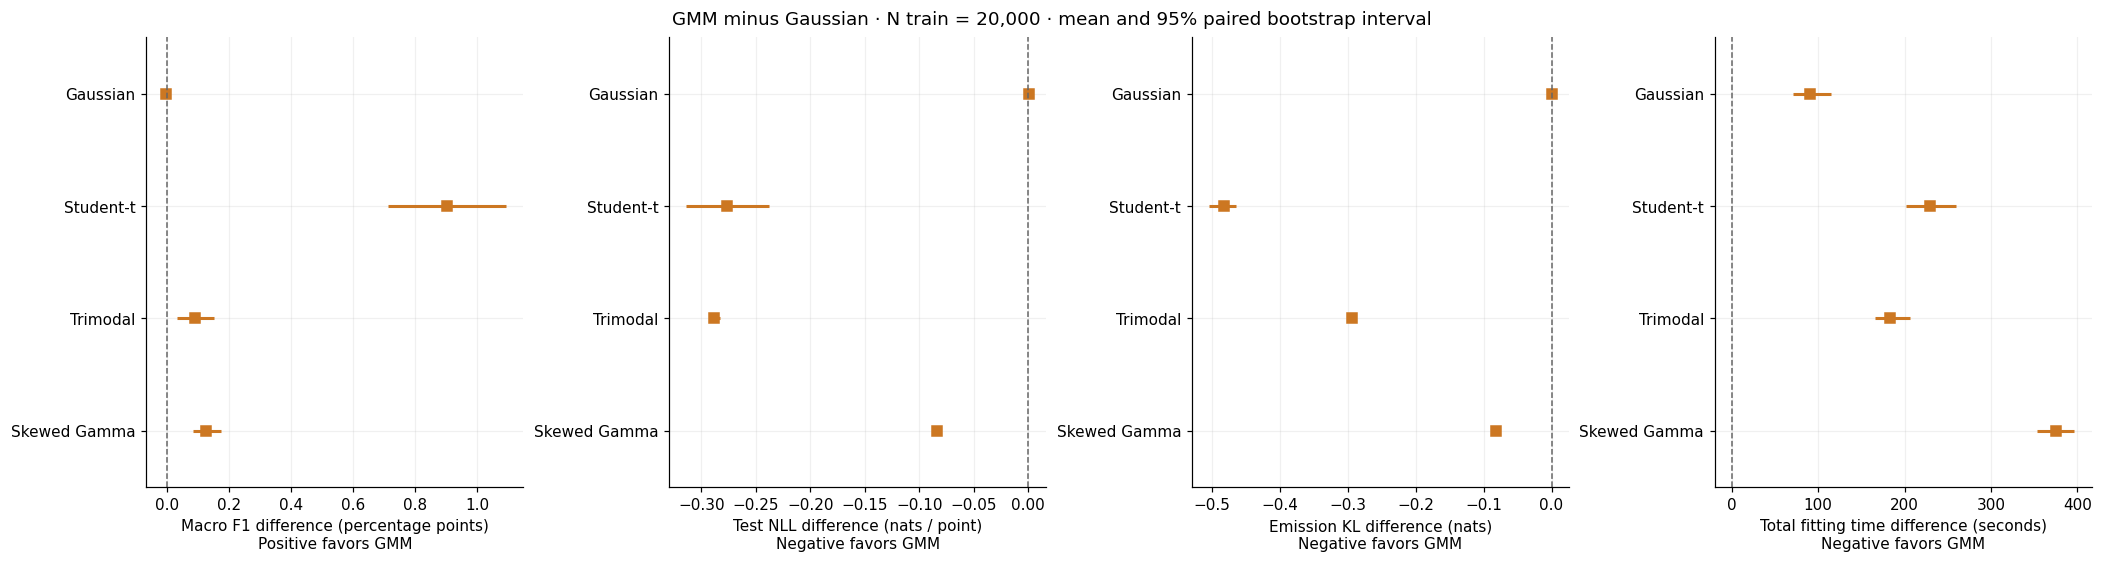

In [8]:
DELTA_METRICS = ["f1_macro", "test_nll", "emission_kl", "total_fit_seconds"]
deltas = paired_differences(CONFIG, paired, DELTA_METRICS)
deltas.to_csv(run_dir / "paired_differences.csv", index=False)
display(deltas.round(5))

fig, axes = plt.subplots(1, 4, figsize=(19, 5), layout="constrained")
for ax, metric, label in zip(axes, DELTA_METRICS, [
    "Macro F1 difference (percentage points)\nPositive favors GMM",
    "Test NLL difference (nats / point)\nNegative favors GMM",
    "Emission KL difference (nats)\nNegative favors GMM",
    "Total fitting time difference (seconds)\nNegative favors GMM",
]):
    part = deltas[(deltas.metric == metric) & (deltas.n_train == max(CONFIG.train_sizes))].set_index("family")
    scale = 100 if metric == "f1_macro" else 1
    for position, family in enumerate(CONFIG.families):
        if family not in part.index:
            ax.text(.02, position, "No pairs", transform=ax.get_yaxis_transform(), va="center")
            continue
        row = part.loc[family]
        if np.isfinite(row.ci_low):
            ax.hlines(position, scale * row.ci_low, scale * row.ci_high, color=MODEL_COLORS["GMM HMM"], linewidth=2)
        ax.plot(scale * row.mean_delta, position, "s", color=MODEL_COLORS["GMM HMM"])
    ax.axvline(0, color=".4", linestyle="--", linewidth=1)
    ax.set_yticks(range(len(CONFIG.families)), CONFIG.families)
    ax.set(xlabel=label, ylim=(len(CONFIG.families) - .5, -.5))
fig.suptitle(f"GMM minus Gaussian · N train = {max(CONFIG.train_sizes):,} · mean and 95% paired bootstrap interval")
show_and_save(fig, "paired_model_differences")

## Confusion matrices and per-state performance

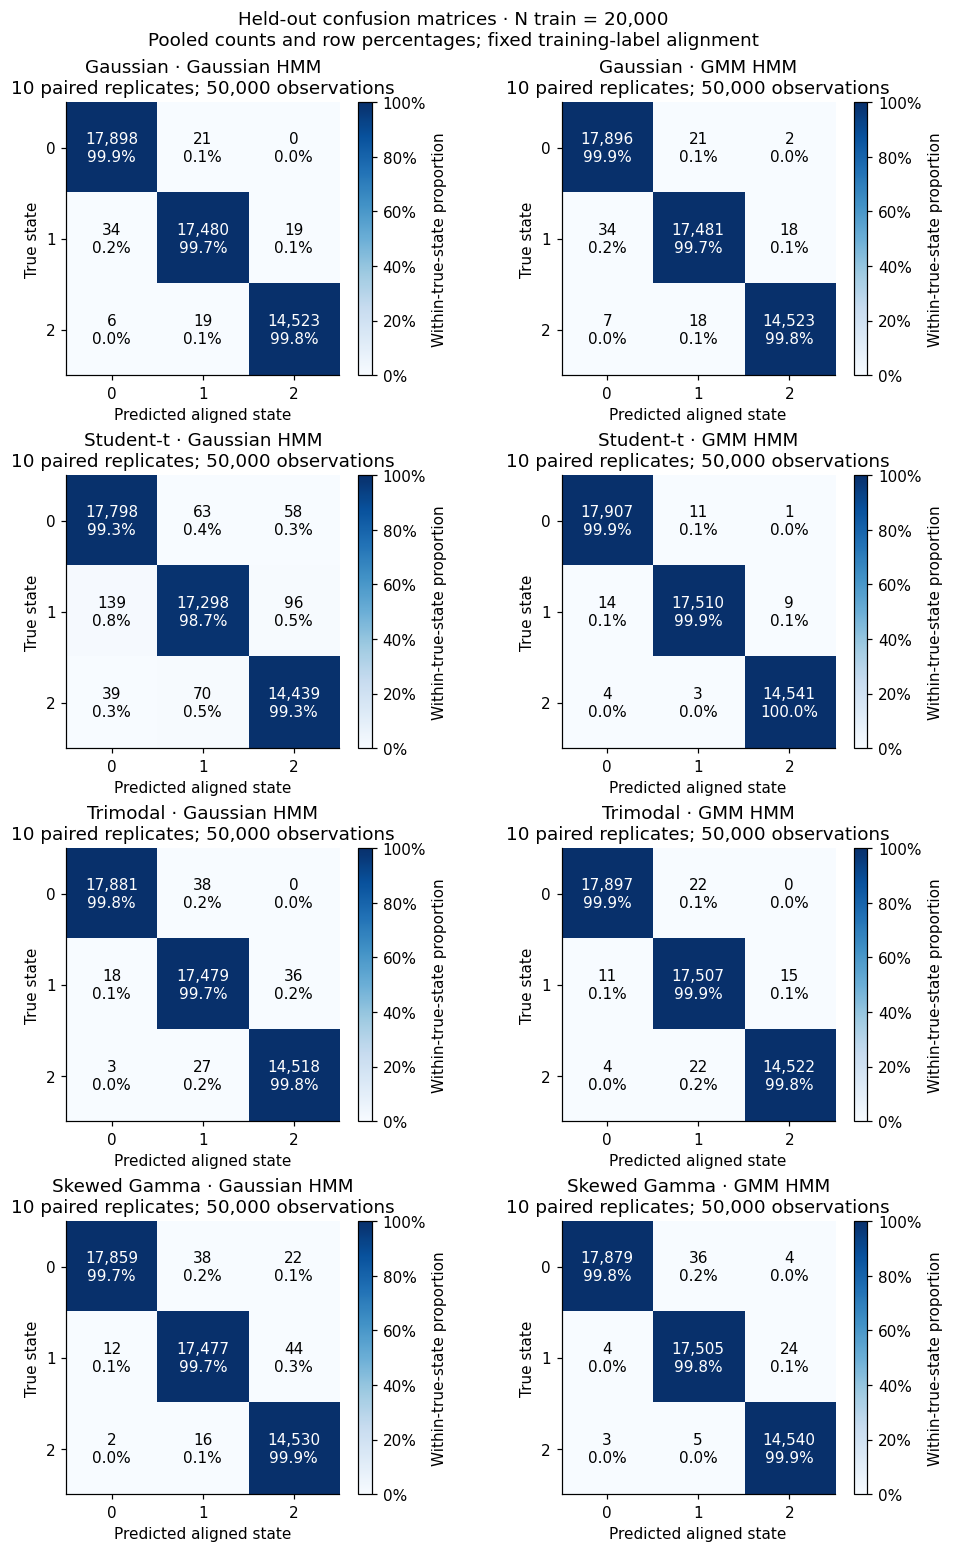

precision  recall      f1  support
family       model        state                                    
Gaussian     GMM HMM      0         0.9976  0.9984  0.9980   1791.9
                          1         0.9978  0.9971  0.9974   1753.3
                          2         0.9985  0.9982  0.9984   1454.8
             Gaussian HMM 0         0.9977  0.9985  0.9981   1791.9
                          1         0.9978  0.9970  0.9974   1753.3
                          2         0.9986  0.9982  0.9984   1454.8
Skewed Gamma GMM HMM      0         0.9996  0.9976  0.9986   1791.9
                          1         0.9976  0.9983  0.9979   1753.3
                          2         0.9978  0.9995  0.9986   1454.8
             Gaussian HMM 0         0.9992  0.9964  0.9978   1791.9
                          1         0.9966  0.9968  0.9967   1753.3
                          2         0.9949  0.9988  0.9969   1454.8
Student-t    GMM HMM      0         0.9989  0.9993  0.9991   1791.9
                          1         0.9991  0.9986  0.9989   1753.3
                          2         0.9991  0.9996  0.9993   1454.8
             Gaussian HMM 0         0.9905  0.9928  0.9916   1791.9
                          1         0.9919  0.9852  0.9884   1753.3
                          2         0.9883  0.9924  0.9903   1454.8
Trimodal     GMM HMM      0         0.9991  0.9985  0.9988   1791.9
                          1         0.9976  0.9983  0.9979   1753.3
                          2         0.9989  0.9980  0.9984   1454.8
             Gaussian HMM 0         0.9988  0.9979  0.9984   1791.9
                          1         0.9959  0.9969  0.9964   1753.3
                          2         0.9975  0.9980  0.9978   1454.8

In [9]:
CONFUSION_N = max(CONFIG.train_sizes)
fig = plot_confusions(CONFIG, run["confusion"], paired, CONFUSION_N)
show_and_save(fig, f"confusion_matrices_n{CONFUSION_N}")

paired_per_state = run["per_state"].merge(paired[PAIR_KEYS + ["model"]],
                                        on=PAIR_KEYS + ["model"], validate="many_to_one")
state_summary = paired_per_state.groupby(["family", "n_train", "model", "state"])[
    ["precision", "recall", "f1", "support"]].agg(["mean", "std", "count"])
state_summary.to_csv(run_dir / "per_state_summary.csv")
display(paired_per_state[paired_per_state.n_train == CONFUSION_N].groupby(
    ["family", "model", "state"])[["precision", "recall", "f1", "support"]].mean().round(4))

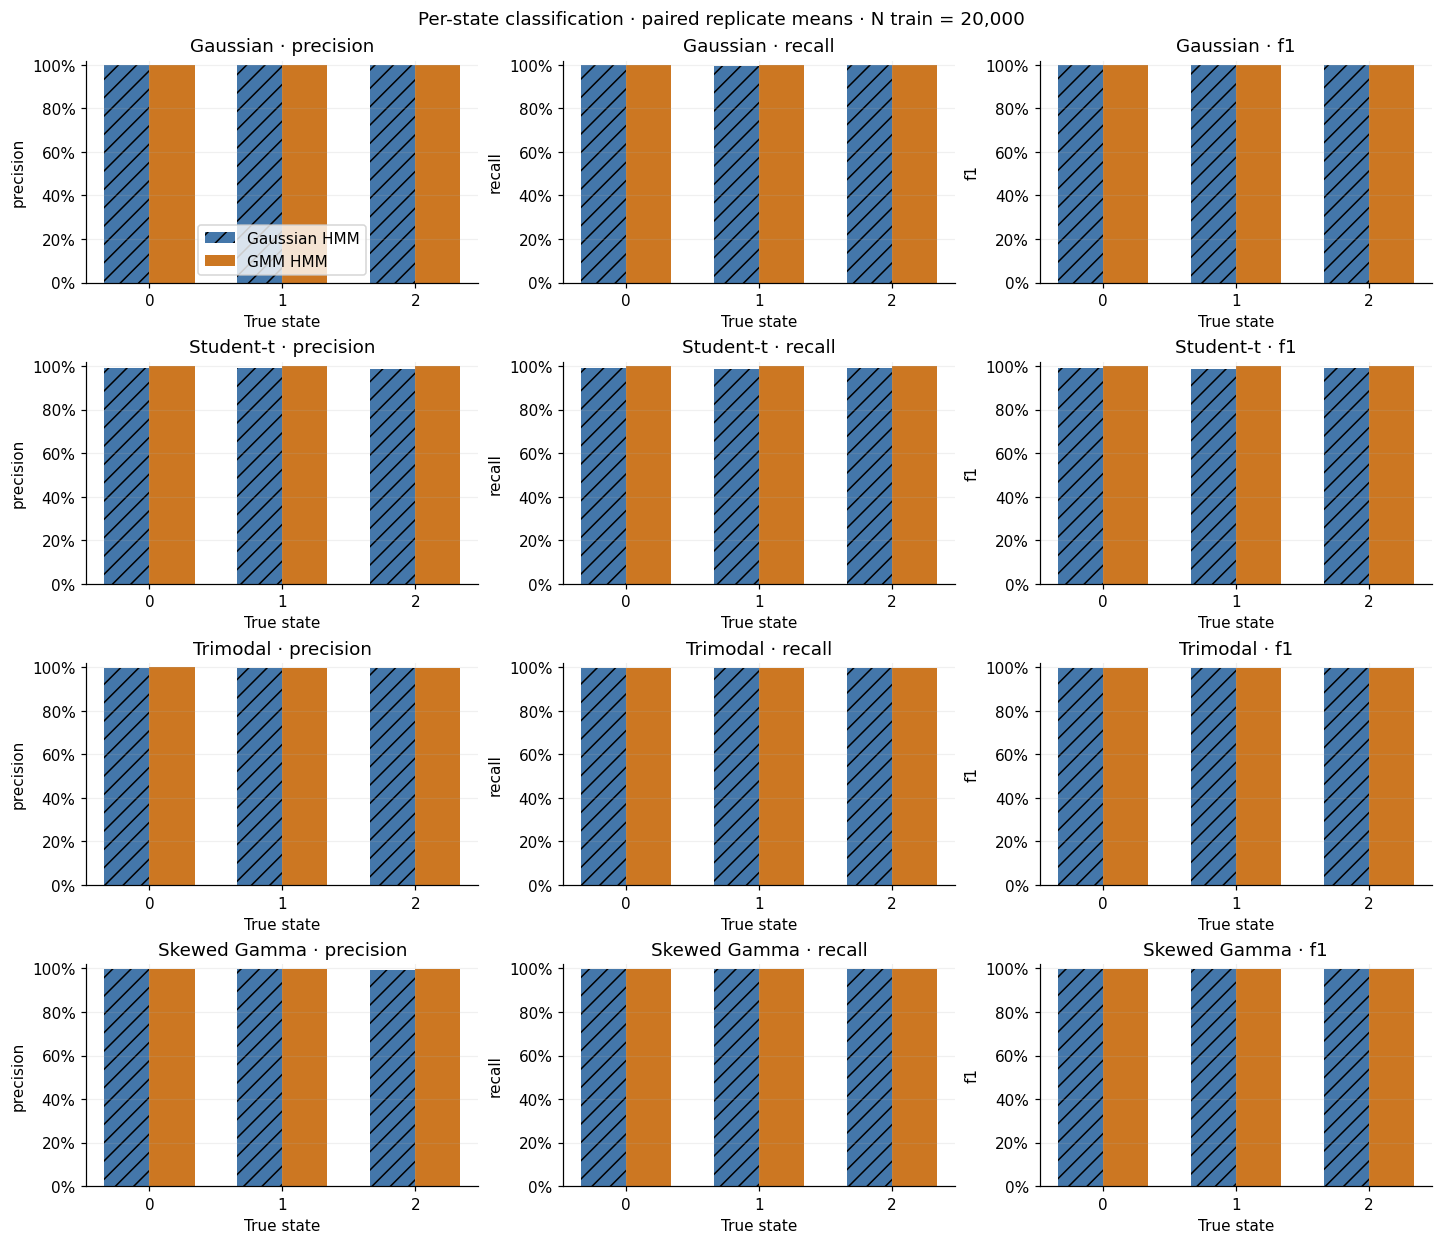

In [10]:
fig, axes = plt.subplots(len(CONFIG.families), 3, figsize=(13, 2.8 * len(CONFIG.families)),
                         squeeze=False, layout="constrained")
for row, family in enumerate(CONFIG.families):
    for column, metric in enumerate(["precision", "recall", "f1"]):
        ax = axes[row, column]
        for model_index, model in enumerate(MODEL_NAMES):
            part = paired_per_state[(paired_per_state.family == family) &
                                    (paired_per_state.model == model) & (paired_per_state.n_train == CONFUSION_N)]
            values = part.groupby("state")[metric].mean().reindex(STATES)
            ax.bar(STATES + (model_index - .5) * .34, values, width=.34,
                   color=MODEL_COLORS[model], hatch="//" if model_index == 0 else "", label=model)
        ax.set(title=f"{family} · {metric}", xlabel="True state", ylabel=metric, ylim=(0, 1.02))
        ax.set_xticks(STATES)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[0, 0].legend()
fig.suptitle(f"Per-state classification · paired replicate means · N train = {CONFUSION_N:,}")
show_and_save(fig, "per_state_classification")

## Illustrative fitted emissions and decoded sequence

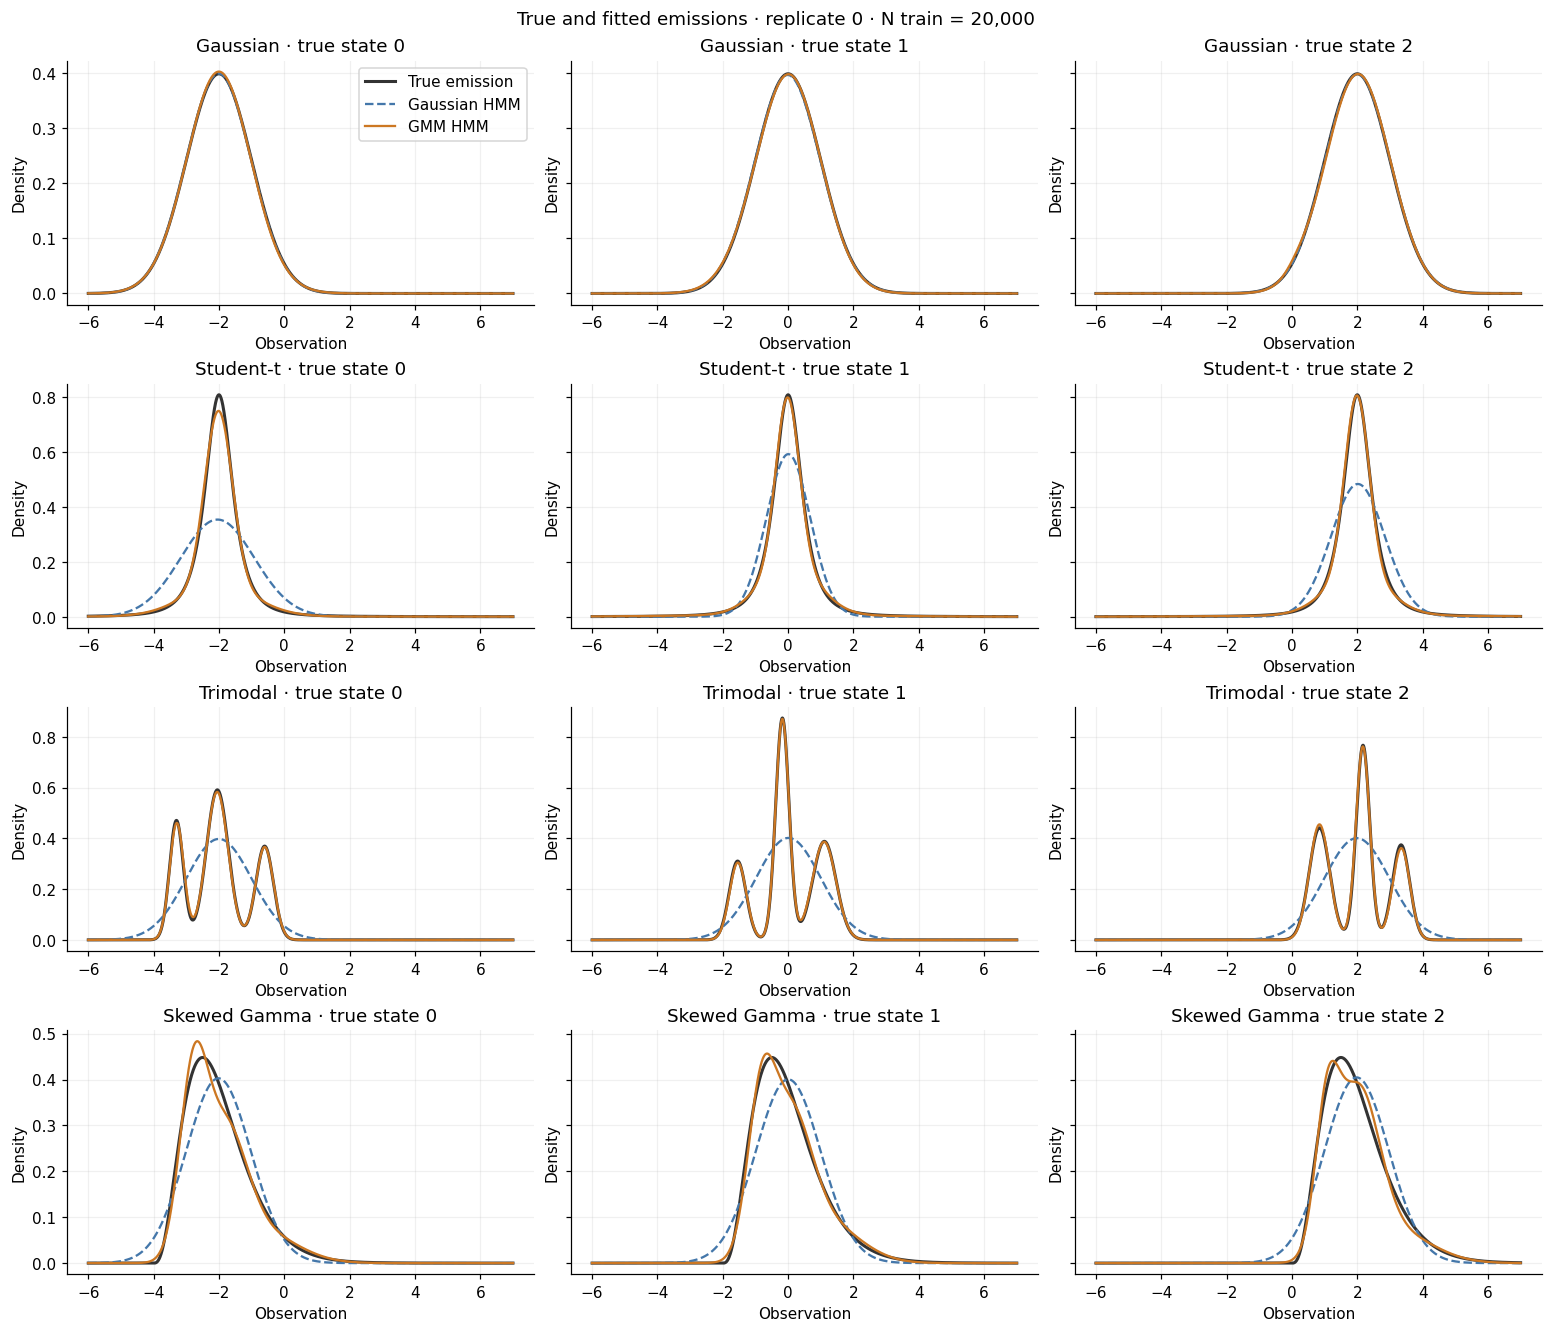

In [11]:
fig, axes = plt.subplots(len(CONFIG.families), 3, figsize=(14, 3 * len(CONFIG.families)),
                         squeeze=False, sharey="row", layout="constrained")
for row, family in enumerate(CONFIG.families):
    grid = np.linspace(-17, 20, 3_000) if family == WIDE_FAMILY else np.linspace(-6, 7, 2_400)
    for k, ax in enumerate(axes[row]):
        ax.plot(grid, np.exp(true_log_density(family, k, grid)), color=".2", linewidth=2, label="True emission")
        missing = []
        for model_name in MODEL_NAMES:
            example = run["examples"].get((family, model_name))
            if example is None:
                missing.append(model_name)
                continue
            order = np.argsort(example["evaluation"].state_mapping)
            log_density = example["model"].emission.log_prob(grid[:, None])[:, order[k]]
            ax.plot(grid, np.exp(log_density), color=MODEL_COLORS[model_name],
                    linestyle=MODEL_STYLES[model_name][1], label=model_name)
        if missing:
            ax.text(.03, .95, "Unavailable: " + ", ".join(missing), transform=ax.transAxes, va="top", fontsize=8)
        ax.set(title=f"{family} · true state {k}", xlabel="Observation", ylabel="Density")
axes[0, 0].legend()
fig.suptitle(f"True and fitted emissions · replicate 0 · N train = {max(CONFIG.train_sizes):,}")
show_and_save(fig, "fitted_emission_densities")

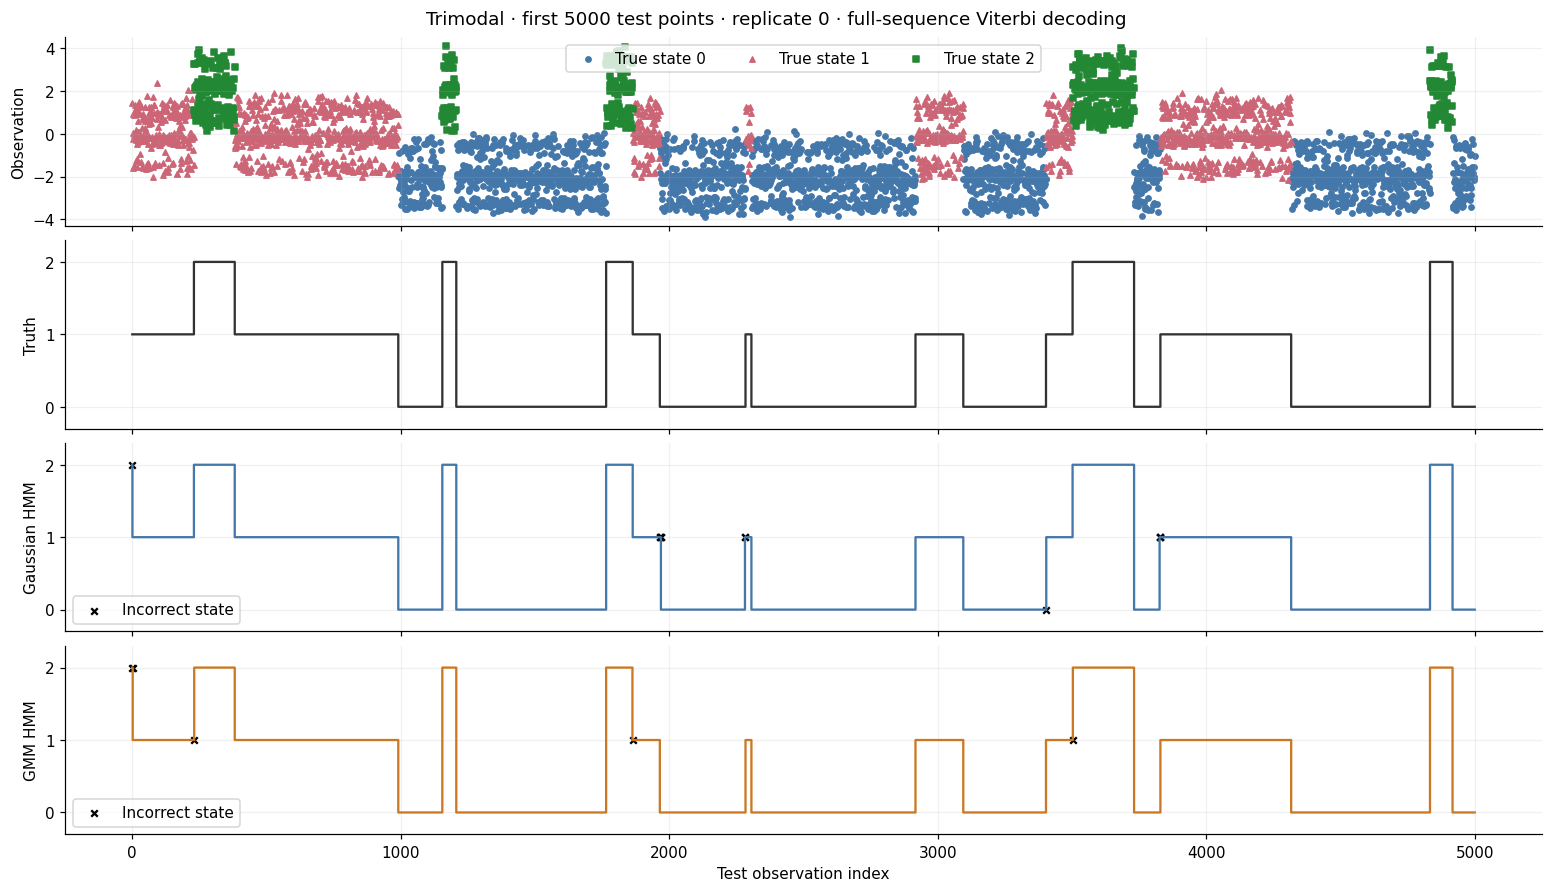

In [21]:
EXAMPLE_FAMILY = "Trimodal"   # Can also use WIDE_FAMILY when include_wide=True.
ZOOM_POINTS = min(5000, CONFIG.n_test)
frame = datasets[0, EXAMPLE_FAMILY]["test"].iloc[:ZOOM_POINTS]
positions = np.arange(ZOOM_POINTS)
fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True, layout="constrained")
for k in STATES:
    mask = frame.state.to_numpy() == k
    axes[0].scatter(positions[mask], frame.x.to_numpy()[mask], s=12,
                    color=STATE_COLORS[k], marker=["o", "^", "s"][k], label=f"True state {k}")
axes[0].set_ylabel("Observation")
axes[0].legend(ncol=3)
axes[1].step(positions, frame.state, where="mid", color=".2")
axes[1].set_ylabel("Truth")
for ax, model_name in zip(axes[2:], MODEL_NAMES):
    example = run["examples"].get((EXAMPLE_FAMILY, model_name))
    if example is None:
        ax.text(.5, .5, "Fit/evaluation unavailable", transform=ax.transAxes, ha="center")
    else:
        predicted = example["evaluation"].aligned_states[0][:ZOOM_POINTS]
        ax.step(positions, predicted, where="mid", color=MODEL_COLORS[model_name])
        wrong = predicted != frame.state.to_numpy()
        ax.scatter(positions[wrong], predicted[wrong], color="black", marker="x", s=18, label="Incorrect state")
        ax.legend()
    ax.set_ylabel(model_name)
for ax in axes[1:]:
    ax.set(yticks=STATES, ylim=(-.3, 2.3))
axes[-1].set_xlabel("Test observation index")
fig.suptitle(f"{EXAMPLE_FAMILY} · first {ZOOM_POINTS} test points · replicate 0 · full-sequence Viterbi decoding")
show_and_save(fig, "example_state_decoding")

## Fit reliability, computation, and remaining diagnostics

In [13]:
fit_diagnostics = attempts.assign(failed=attempts.status.ne("ok")).groupby(
    ["family", "n_train", "model"]).agg(
    starts=("status", "size"), failures=("failed", "sum"), converged_starts=("converged", "sum"),
    mean_iterations=("iterations", "mean"), total_fit_seconds=("fit_seconds", "sum"),
    likelihood_decreases=("likelihood_decreases", "sum"))
selected_diagnostics = results.groupby(["family", "n_train", "model"]).agg(
    evaluations=("evaluation_status", "size"), selected_converged=("converged", "sum"))
fit_diagnostics = fit_diagnostics.join(selected_diagnostics)
fit_diagnostics.to_csv(run_dir / "fit_diagnostics.csv")
display(fit_diagnostics.round(3))
display(paired.groupby(["family", "n_train", "model"])[[
    "switch_precision", "switch_recall", "switch_f1", "true_switch_rate", "predicted_switch_rate",
    "state_log_loss", "state_log_loss_capped_fraction", "state_zero_probability_fraction",
    "mean_rmse", "variance_rmse", "kl_quad_error_max", "total_fit_seconds"
]].mean().round(6))

start_variability = attempts[attempts.status == "ok"].groupby(PAIR_KEYS + ["model"]).train_ll.agg(["min", "max"])
start_variability["range_per_observation"] = (start_variability["max"] - start_variability["min"]) / start_variability.index.get_level_values("n_train")
start_variability.to_csv(run_dir / "initialization_variability.csv")
display(start_variability.groupby(["family", "n_train", "model"])[["range_per_observation"]].mean().round(6))
for label, frame, column in [("Fit", attempts, "warnings"), ("Evaluation", results, "evaluation_warnings")]:
    if column in frame:
        messages = frame[column].explode().dropna()
        print(f"{label} warnings: {len(messages)}")
        if len(messages):
            display(messages.value_counts().head(20).to_frame("count"))
failed = results[results.evaluation_status != "ok"]
print("Evaluation outcomes:", results.evaluation_status.value_counts().to_dict())
if not failed.empty:
    display(failed.reindex(columns=PAIR_KEYS + ["model", "evaluation_status", "error"]).head(20))
print(f"All detailed failures and warnings are saved in {run_dir}")

starts  failures  converged_starts  \
family       n_train model                                              
Gaussian     20000   GMM HMM          100         0               100   
                     Gaussian HMM     100         0               100   
Skewed Gamma 20000   GMM HMM          100         0               100   
                     Gaussian HMM     100         0               100   
Student-t    20000   GMM HMM          100         0               100   
                     Gaussian HMM     100         0               100   
Trimodal     20000   GMM HMM          100         0               100   
                     Gaussian HMM     100         0               100   

                                   mean_iterations  total_fit_seconds  \
family       n_train model                                              
Gaussian     20000   GMM HMM                 69.22           1309.888   
                     Gaussian HMM            22.61            408.036   
Skewed Gamma 20000   GMM HMM                229.08           4252.171   
                     Gaussian HMM            28.17            499.470   
Student-t    20000   GMM HMM                157.19           2906.414   
                     Gaussian HMM            34.99            606.669   
Trimodal     20000   GMM HMM                116.69           2182.185   
                     Gaussian HMM            19.39            351.251   

                                   likelihood_decreases  evaluations  \
family       n_train model                                             
Gaussian     20000   GMM HMM                          0           10   
                     Gaussian HMM                     0           10   
Skewed Gamma 20000   GMM HMM                          0           10   
                     Gaussian HMM                     0           10   
Student-t    20000   GMM HMM                          0           10   
                     Gaussian HMM                     0           10   
Trimodal     20000   GMM HMM                          0           10   
                     Gaussian HMM                     0           10   

                                   selected_converged  
family       n_train model                             
Gaussian     20000   GMM HMM                       10  
                     Gaussian HMM                  10  
Skewed Gamma 20000   GMM HMM                       10  
                     Gaussian HMM                  10  
Student-t    20000   GMM HMM                       10  
                     Gaussian HMM                  10  
Trimodal     20000   GMM HMM                       10  
                     Gaussian HMM                  10

switch_precision  switch_recall  switch_f1  \
family       n_train model                                                      
Gaussian     20000   GMM HMM               0.744267       0.762834   0.753164   
                     Gaussian HMM          0.744267       0.762834   0.753164   
Skewed Gamma 20000   GMM HMM               0.774650       0.792695   0.783387   
                     Gaussian HMM          0.622572       0.742738   0.676484   
Student-t    20000   GMM HMM               0.885915       0.917332   0.901031   
                     Gaussian HMM          0.299248       0.888959   0.442431   
Trimodal     20000   GMM HMM               0.799630       0.813429   0.806376   
                     Gaussian HMM          0.698608       0.707958   0.703178   

                                   true_switch_rate  predicted_switch_rate  \
family       n_train model                                                   
Gaussian     20000   GMM HMM               0.004761               0.004881   
                     Gaussian HMM          0.004761               0.004881   
Skewed Gamma 20000   GMM HMM               0.004761               0.004881   
                     Gaussian HMM          0.004761               0.005721   
Student-t    20000   GMM HMM               0.004761               0.004941   
                     Gaussian HMM          0.004761               0.014723   
Trimodal     20000   GMM HMM               0.004761               0.004841   
                     Gaussian HMM          0.004761               0.004821   

                                   state_log_loss  \
family       n_train model                          
Gaussian     20000   GMM HMM             0.007712   
                     Gaussian HMM        0.007598   
Skewed Gamma 20000   GMM HMM             0.006632   
                     Gaussian HMM        0.010727   
Student-t    20000   GMM HMM             0.005488   
                     Gaussian HMM        0.080654   
Trimodal     20000   GMM HMM             0.005715   
                     Gaussian HMM        0.007924   

                                   state_log_loss_capped_fraction  \
family       n_train model                                          
Gaussian     20000   GMM HMM                              0.00006   
                     Gaussian HMM                         0.00004   
Skewed Gamma 20000   GMM HMM                              0.00008   
                     Gaussian HMM                         0.00006   
Student-t    20000   GMM HMM                              0.00006   
                     Gaussian HMM                         0.00058   
Trimodal     20000   GMM HMM                              0.00008   
                     Gaussian HMM                         0.00008   

                                   state_zero_probability_fraction  mean_rmse  \
family       n_train model                                                      
Gaussian     20000   GMM HMM                               0.00002   0.010545   
                     Gaussian HMM                          0.00000   0.010530   
Skewed Gamma 20000   GMM HMM                               0.00006   0.009727   
                     Gaussian HMM                          0.00000   0.012688   
Student-t    20000   GMM HMM                               0.00006   0.010419   
                     Gaussian HMM                          0.00000   0.025277   
Trimodal     20000   GMM HMM                               0.00008   0.009048   
                     Gaussian HMM                          0.00000   0.009012   

                                   variance_rmse  kl_quad_error_max  \
family       n_train model                                            
Gaussian     20000   GMM HMM            0.016859                0.0   
                     Gaussian HMM       0.016853                0.0   
Skewed Gamma 20000   GMM HMM            0.020612                0.0   
                     Gaussian HMM       0.030062       

range_per_observation
family       n_train model                              
Gaussian     20000   GMM HMM                    0.077181
                     Gaussian HMM               0.152796
Skewed Gamma 20000   GMM HMM                    0.067099
                     Gaussian HMM               0.167653
Student-t    20000   GMM HMM                    0.170809
                     Gaussian HMM               0.183768
Trimodal     20000   GMM HMM                    0.228196
                     Gaussian HMM               0.124196

Fit warnings: 0
Evaluation warnings: 0
Evaluation outcomes: {'ok': 80}
All detailed failures and warnings are saved in /Users/leoyang/Desktop/School/CSCD94/data/synthetic/gmm_synthetic_experiments/20261024T212804Z-4r1by0vo


### Reference: the best possible single-Gaussian emission KL

The Gaussian matching the true mean and variance minimizes KL from the true emission to a single Gaussian. This floor explains irreducible shape mismatch for Gaussian emissions.

In [14]:
floor_rows = []
for family in CONFIG.families:
    means, variances = true_moments(family)
    for k in STATES:
        value, error = emission_kl(CONFIG, family, k, np.array([1.]),
                                   np.array([means[k]]), np.array([variances[k]]))
        floor_rows.append({"family": family, "state": int(k), "gaussian_kl_floor": value, "quad_error": error})
floors = pd.DataFrame(floor_rows)
assert abs(floors[floors.family == "Gaussian"].gaussian_kl_floor.max()) < 1e-7
floors.to_csv(run_dir / "gaussian_kl_floor.csv", index=False)
comparison_kl = paired.groupby(["family", "n_train", "model"]).emission_kl.mean().rename("fitted_kl").to_frame()
comparison_kl = comparison_kl.join(floors.groupby("family").gaussian_kl_floor.mean(), on="family")
comparison_kl["kl_minus_gaussian_floor"] = comparison_kl.fitted_kl - comparison_kl.gaussian_kl_floor
comparison_kl.to_csv(run_dir / "kl_vs_gaussian_floor.csv")
display(comparison_kl.round(6))

fitted_kl  gaussian_kl_floor  \
family       n_train model                                        
Gaussian     20000   GMM HMM        0.000380           0.000000   
                     Gaussian HMM   0.000155           0.000000   
Skewed Gamma 20000   GMM HMM        0.006788           0.088679   
                     Gaussian HMM   0.089048           0.088679   
Student-t    20000   GMM HMM        0.010459           0.375897   
                     Gaussian HMM   0.492800           0.375897   
Trimodal     20000   GMM HMM        0.000505           0.294603   
                     Gaussian HMM   0.294689           0.294603   

                                   kl_minus_gaussian_floor  
family       n_train model                                  
Gaussian     20000   GMM HMM                      0.000380  
                     Gaussian HMM                 0.000155  
Skewed Gamma 20000   GMM HMM                     -0.081891  
                     Gaussian HMM                 0.000368  
Student-t    20000   GMM HMM                     -0.365438  
                     Gaussian HMM                 0.116902  
Trimodal     20000   GMM HMM                     -0.294098  
                     Gaussian HMM                 0.000085

## Mean-separated regimes: clean versus perturbed test observations

Use the new persistent mean-regime fits saved above; no refitting is performed in this section.

For each training prefix, add independent Gaussian measurement noise with a linearly increasing standard deviation:

$$
X_t^{(\lambda)}=X_t+\lambda s_{\mathrm{train}}\frac{t}{T-1}\eta_t,
\qquad \eta_t\sim N(0,1),\quad t=0,\ldots,T-1.
$$

Here $s_{\mathrm{train}}$ is the pooled training standard deviation and $\lambda\in\{0.10,0.25,0.50\}$. Both models receive identical perturbations; severity levels reuse the same noise vector. True labels, fitted parameters, and training-derived alignment remain fixed. Inference is offline. Parameter recovery and clean-emission KL are unchanged and are not recomputed as noise-degradation metrics.

In [17]:
from pathlib import Path
import json
import sys
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

mean_noise_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src/flexible_emission_hmm").is_dir()
)
for path in (mean_noise_root / "src", mean_noise_root / "notebooks"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

mean_reference = persistence_reference
from flexible_emission_hmm import ExactInference, StateParameters
from model_evaluation.synthetic.state_alignment import state_log_loss_metrics
from volatility_markov_comparison import make_test_variants

MEAN_NOISE_LEVELS = (0.10, 0.25, 0.50)
mean_noise_run = Path(run_dir).resolve()
mean_noise_manifest = json.loads((mean_noise_run / "manifest.json").read_text())
mean_noise_config_values = dict(mean_noise_manifest["settings"])
mean_noise_config_values["train_sizes"] = tuple(mean_noise_config_values["train_sizes"])
mean_noise_config = mean_reference.ExperimentConfig(**mean_noise_config_values)
# The existing noise helper only needs noise_levels and master_seed.
mean_noise_settings = SimpleNamespace(
    noise_levels=MEAN_NOISE_LEVELS,
    master_seed=mean_noise_config.master_seed,
)
mean_noise_saved = pd.read_csv(mean_noise_run / "results.csv")
mean_noise_pairs = mean_reference.paired_results(mean_noise_saved)
if mean_noise_pairs.empty:
    raise ValueError("No successful saved mean-regime model pairs")
if mean_noise_pairs.duplicated(mean_reference.PAIR_KEYS + ["model"]).any():
    raise ValueError("Duplicate saved evaluations")
mean_noise_parameters = {
    (row["family"], row["n_train"], row["replicate"], row["model"]): row
    for row in json.loads((mean_noise_run / "parameters.json").read_text())
}
mean_noise_datasets = {
    (row["family"], row["replicate"]): row["file"]
    for row in json.loads((mean_noise_run / "dataset_index.json").read_text())
}
mean_noise_output = mean_noise_run / "mean_regime_perturbation"
mean_noise_output.mkdir(exist_ok=True)
print(f"Source fits: {mean_noise_run}")
print(f"Paired saved fits: {len(mean_noise_pairs)}; no training is performed")


Source fits: /Users/leoyang/Desktop/School/CSCD94/data/synthetic/gmm_synthetic_experiments/20261024T212804Z-4r1by0vo
Paired saved fits: 80; no training is performed


### Replay clean predictions, then evaluate the same fits under noise

In [16]:
mean_noise_rows = []
mean_noise_examples = {}
mean_noise_engine = ExactInference()
mean_noise_conditions = ["clean"] + [f"noise_{level:g}" for level in MEAN_NOISE_LEVELS]
for (family, replicate), group in mean_noise_pairs.groupby(["family", "replicate"]):
    with np.load(mean_noise_run / mean_noise_datasets[family, replicate]) as archive:
        train_values = archive["train__x"].reshape(-1)
        test = pd.DataFrame({
            "x": archive["test__x"].reshape(-1),
            "state": archive["test__state"].astype(int),
        })
    for n_train, fits in group.groupby("n_train"):
        train = pd.DataFrame({"x": train_values[:int(n_train)]})
        variants, train_scale = make_test_variants(
            mean_noise_settings, train, test, int(replicate), family, int(n_train)
        )
        for saved in fits.to_dict("records"):
            key = (family, int(n_train), int(replicate), saved["model"])
            record = mean_noise_parameters[key]
            mapping = np.asarray(record["mapping_learned_to_true"], dtype=int)
            order = np.argsort(mapping)
            start = np.asarray(record["aligned_initial_probs"])
            transitions = np.asarray(record["aligned_transitions"])
            states = StateParameters(
                start[mapping], transitions[np.ix_(mapping, mapping)]
            )
            clean_verified = False
            for condition, frame in variants.items():
                row = dict(zip(mean_reference.PAIR_KEYS + ["model"], key))
                row.update(
                    condition=condition, evaluation_status="failed",
                    training_scale=train_scale,
                    noise_std_end=float(frame.noise_std.iloc[-1]),
                    noise_std_rms=float(np.sqrt(np.mean(frame.noise_std ** 2))),
                )
                try:
                    if condition != "clean" and not clean_verified:
                        raise ValueError("Clean replay failed; noisy evaluation withheld")
                    aligned_emissions = np.column_stack([
                        mean_reference.component_log_density(
                            frame.x.to_numpy(), np.asarray(record["weights"])[state],
                            np.asarray(record["means"])[state],
                            np.asarray(record["variances"])[state],
                        ) for state in mean_reference.STATES
                    ])
                    emissions = aligned_emissions[:, mapping]
                    inference = mean_noise_engine.infer(states, emissions)
                    posterior = inference.responsibilities[:, order]
                    predicted = mapping[mean_noise_engine.decode(states, emissions)]
                    truth = frame.state.to_numpy()
                    scores, _, _ = mean_reference.classification_metrics(truth, predicted)
                    row.update(scores, **state_log_loss_metrics(posterior, truth))
                    true_switches = int(np.count_nonzero(np.diff(truth)))
                    inferred_switches = int(np.count_nonzero(np.diff(predicted)))
                    row.update(
                        aligned_accuracy=float(np.mean(predicted == truth)),
                        test_nll=-inference.log_likelihood / len(truth),
                        state_brier_score=float(np.mean(np.sum(
                            (posterior - np.eye(3)[truth]) ** 2, axis=1
                        ))),
                        mean_true_state_posterior=float(
                            posterior[np.arange(len(truth)), truth].mean()
                        ),
                        true_switches=true_switches,
                        inferred_switches=inferred_switches,
                        absolute_switch_count_error=abs(inferred_switches - true_switches),
                    )
                    if condition == "clean":
                        for metric in ("test_nll", "aligned_accuracy", "state_log_loss"):
                            np.testing.assert_allclose(
                                row[metric], saved[metric], rtol=1e-7, atol=1e-8,
                                err_msg=f"Clean replay mismatch: {key}, {metric}",
                            )
                        clean_verified = True
                    row["evaluation_status"] = "ok"
                    if replicate == 0 and n_train == max(mean_noise_config.train_sizes):
                        mean_noise_examples[family, saved["model"], condition] = {
                            "x": frame.x.to_numpy(), "truth": truth,
                            "predicted": predicted,
                        }
                except Exception as exc:
                    row["error"] = f"{type(exc).__name__}: {exc}"
                mean_noise_rows.append(row)
    print(f"Evaluated {family}, replicate {replicate}")

mean_noise_results = pd.DataFrame(mean_noise_rows)
mean_noise_results.to_csv(mean_noise_output / "results.csv", index=False)
mean_noise_keys = mean_reference.PAIR_KEYS
mean_noise_success = mean_noise_results.query("evaluation_status == 'ok'")
mean_noise_counts = mean_noise_success.groupby(mean_noise_keys).size()
mean_noise_complete = mean_noise_counts[
    mean_noise_counts == len(mean_reference.MODEL_NAMES) * len(mean_noise_conditions)
].reset_index()[mean_noise_keys]
mean_noise_paired = mean_noise_success.merge(
    mean_noise_complete, on=mean_noise_keys, validate="many_to_one"
)
mean_noise_coverage = mean_noise_results.groupby(
    ["family", "n_train", "model", "condition"]
).evaluation_status.agg(attempted="size", successful=lambda x: (x == "ok").sum())
mean_noise_coverage.to_csv(mean_noise_output / "coverage.csv")
display(mean_noise_coverage)
if mean_noise_paired.empty:
    raise RuntimeError("No complete pairs; inspect results.csv for replay failures")


Evaluated Gaussian, replicate 0
Evaluated Gaussian, replicate 1
Evaluated Gaussian, replicate 2
Evaluated Gaussian, replicate 3
Evaluated Gaussian, replicate 4
Evaluated Gaussian, replicate 5
Evaluated Gaussian, replicate 6
Evaluated Gaussian, replicate 7
Evaluated Gaussian, replicate 8
Evaluated Gaussian, replicate 9
Evaluated Skewed Gamma, replicate 0
Evaluated Skewed Gamma, replicate 1
Evaluated Skewed Gamma, replicate 2
Evaluated Skewed Gamma, replicate 3
Evaluated Skewed Gamma, replicate 4
Evaluated Skewed Gamma, replicate 5
Evaluated Skewed Gamma, replicate 6
Evaluated Skewed Gamma, replicate 7
Evaluated Skewed Gamma, replicate 8
Evaluated Skewed Gamma, replicate 9
Evaluated Student-t, replicate 0
Evaluated Student-t, replicate 1
Evaluated Student-t, replicate 2
Evaluated Student-t, replicate 3
Evaluated Student-t, replicate 4
Evaluated Student-t, replicate 5
Evaluated Student-t, replicate 6
Evaluated Student-t, replicate 7
Evaluated Student-t, replicate 8
Evaluated Student-t, re

attempted  successful
family       n_train model        condition                        
Gaussian     20000   GMM HMM      clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10
                     Gaussian HMM clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10
Skewed Gamma 20000   GMM HMM      clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10
                     Gaussian HMM clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10
Student-t    20000   GMM HMM      clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10
                     Gaussian HMM clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10
Trimodal     20000   GMM HMM      clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10
                     Gaussian HMM clean              10          10
                                  noise_0.1          10          10
                                  noise_0.25         10          10
                                  noise_0.5          10          10

### Clean and perturbed scores and paired differences

In [18]:
mean_noise_metrics = [
    "aligned_accuracy", "f1_macro", "test_nll", "state_log_loss",
    "state_brier_score", "mean_true_state_posterior", "switch_f1",
    "absolute_switch_count_error",
]
mean_noise_summary = mean_noise_paired.groupby(
    ["family", "n_train", "model", "condition"]
)[mean_noise_metrics].agg(["mean", "std", "count"])
mean_noise_summary.to_csv(mean_noise_output / "summary.csv")
display(mean_noise_paired.groupby(
    ["family", "n_train", "model", "condition"]
)[mean_noise_metrics].mean().round(4))
mean_noise_index = mean_noise_keys + ["model"]
mean_noise_clean = mean_noise_paired.query("condition == 'clean'")
mean_noise_joined = mean_noise_paired.query("condition != 'clean'").merge(
    mean_noise_clean[mean_noise_index + mean_noise_metrics],
    on=mean_noise_index, suffixes=("", "_clean"), validate="many_to_one",
)
mean_noise_changes = mean_noise_joined[mean_noise_index + ["condition"]].copy()
for metric in mean_noise_metrics:
    mean_noise_changes[metric] = (
        mean_noise_joined[metric] - mean_noise_joined[f"{metric}_clean"]
    )
mean_noise_changes.to_csv(mean_noise_output / "noisy_minus_clean.csv", index=False)
mean_noise_deltas = []
for condition in mean_noise_conditions:
    differences = mean_reference.paired_differences(
        mean_noise_config,
        mean_noise_paired[mean_noise_paired.condition == condition],
        mean_noise_metrics,
    )
    differences["condition"] = condition
    mean_noise_deltas.append(differences)
mean_noise_deltas = pd.concat(mean_noise_deltas, ignore_index=True)
mean_noise_deltas.to_csv(mean_noise_output / "gmm_minus_gaussian.csv", index=False)
display(mean_noise_deltas[
    (mean_noise_deltas.n_train == max(mean_noise_config.train_sizes))
    & (mean_noise_deltas.metric == "f1_macro")
].round(4))
(mean_noise_output / "manifest.json").write_text(json.dumps({
    "source_run": str(mean_noise_run),
    "noise_levels": MEAN_NOISE_LEVELS,
    "noise_schedule": "lambda * training_std(ddof=0) * t/(T-1)",
    "master_seed": mean_noise_config.master_seed,
    "seed_parts": ["measurement_noise", "replicate", "family", "n_train"],
    "alignment": "saved training permutation; original state order for inference",
    "comparison": "complete model pairs across every noise condition",
    "bootstrap_samples": mean_noise_config.bootstrap_samples,
}, indent=2))


aligned_accuracy  f1_macro  \
family       n_train model        condition                                
Gaussian     20000   GMM HMM      clean                 0.9980    0.9979   
                                  noise_0.1             0.9981    0.9980   
                                  noise_0.25            0.9983    0.9983   
                                  noise_0.5             0.9968    0.9967   
                     Gaussian HMM clean                 0.9980    0.9980   
                                  noise_0.1             0.9982    0.9981   
                                  noise_0.25            0.9984    0.9983   
                                  noise_0.5             0.9971    0.9969   
Skewed Gamma 20000   GMM HMM      clean                 0.9985    0.9984   
                                  noise_0.1             0.9985    0.9984   
                                  noise_0.25            0.9982    0.9981   
                                  noise_0.5             0.9926    0.9924   
                     Gaussian HMM clean                 0.9973    0.9971   
                                  noise_0.1             0.9972    0.9970   
                                  noise_0.25            0.9967    0.9965   
                                  noise_0.5             0.9943    0.9940   
Student-t    20000   GMM HMM      clean                 0.9992    0.9991   
                                  noise_0.1             0.9991    0.9990   
                                  noise_0.25            0.9989    0.9989   
                                  noise_0.5             0.9975    0.9972   
                     Gaussian HMM clean                 0.9907    0.9901   
                                  noise_0.1             0.9908    0.9902   
                                  noise_0.25            0.9905    0.9899   
                                  noise_0.5             0.9805    0.9792   
Trimodal     20000   GMM HMM      clean                 0.9985    0.9984   
                                  noise_0.1             0.9982    0.9981   
                                  noise_0.25            0.9958    0.9956   
                                  noise_0.5             0.9727    0.9715   
                     Gaussian HMM clean                 0.9976    0.9975   
                                  noise_0.1             0.9975    0.9975   
                                  noise_0.25            0.9973    0.9972   
                                  noise_0.5             0.9961    0.9960   

                                              test_nll  state_log_loss  \
family       n_train model        condition                              
Gaussian     20000   GMM HMM      clean         1.4574          0.0077   
                                  noise_0.1     1.4638          0.0076   
                                  noise_0.25    1.4959          0.0080   
                                  noise_0.5     1.6086          0.0121   
                     Gaussian HMM clean         1.4571          0.0076   
                                  noise_0.1     1.4635          0.0075   
                                  noise_0.25    1.4955          0.0079   
                                  noise_0.5     1.6081          0.0117   
Skewed Gamma 20000   GMM HMM      clean         1.3692          0.0066   
                                  noise_0.1     1.3807          0.0067   
                                  noise_0.25    1.4359          0.0078   
                                  noise_0.5     1.6180          0.0277   
                     Gaussian HMM clean         1.4525          0.0107   
                                  noise_0.1     1.4598          0.0110   
                                  noise_0.25    1.4941          0.0123   
                                  noise_0.5     1.6126          0.0192   
Student-t    20000   GMM HMM      clean         1.0808          0.0055   
                                  noise_0.1     1.0985 

,family,n_train,metric,n_pairs,mean_delta,ci_low,ci_high,condition
1,Gaussian,20000,f1_macro,10,-0.0000,-0.0001,0.0001,clean
9,Skewed Gamma,20000,f1_macro,10,0.0013,0.0008,0.0018,clean
17,Student-t,20000,f1_macro,10,0.0090,0.0071,0.0109,clean
25,Trimodal,20000,f1_macro,10,0.0009,0.0003,0.0015,clean
33,Gaussian,20000,f1_macro,10,-0.0000,-0.0001,0.0000,noise_0.1
41,Skewed Gamma,20000,f1_macro,10,0.0014,0.0008,0.0022,noise_0.1
49,Student-t,20000,f1_macro,10,0.0088,0.0070,0.0107,noise_0.1
57,Trimodal,20000,f1_macro,10,0.0007,0.0002,0.0013,noise_0.1
65,Gaussian,20000,f1_macro,10,-0.0000,-0.0001,0.0000,noise_0.25
73,Skewed Gamma,20000,f1_macro,10,0.0016,0.0009,0.0024,noise_0.25


533

### Robustness curves at the largest training size

Error bars show one sample standard deviation across independent replications. Noise percentages denote the final added-noise standard deviation relative to pooled training standard deviation.

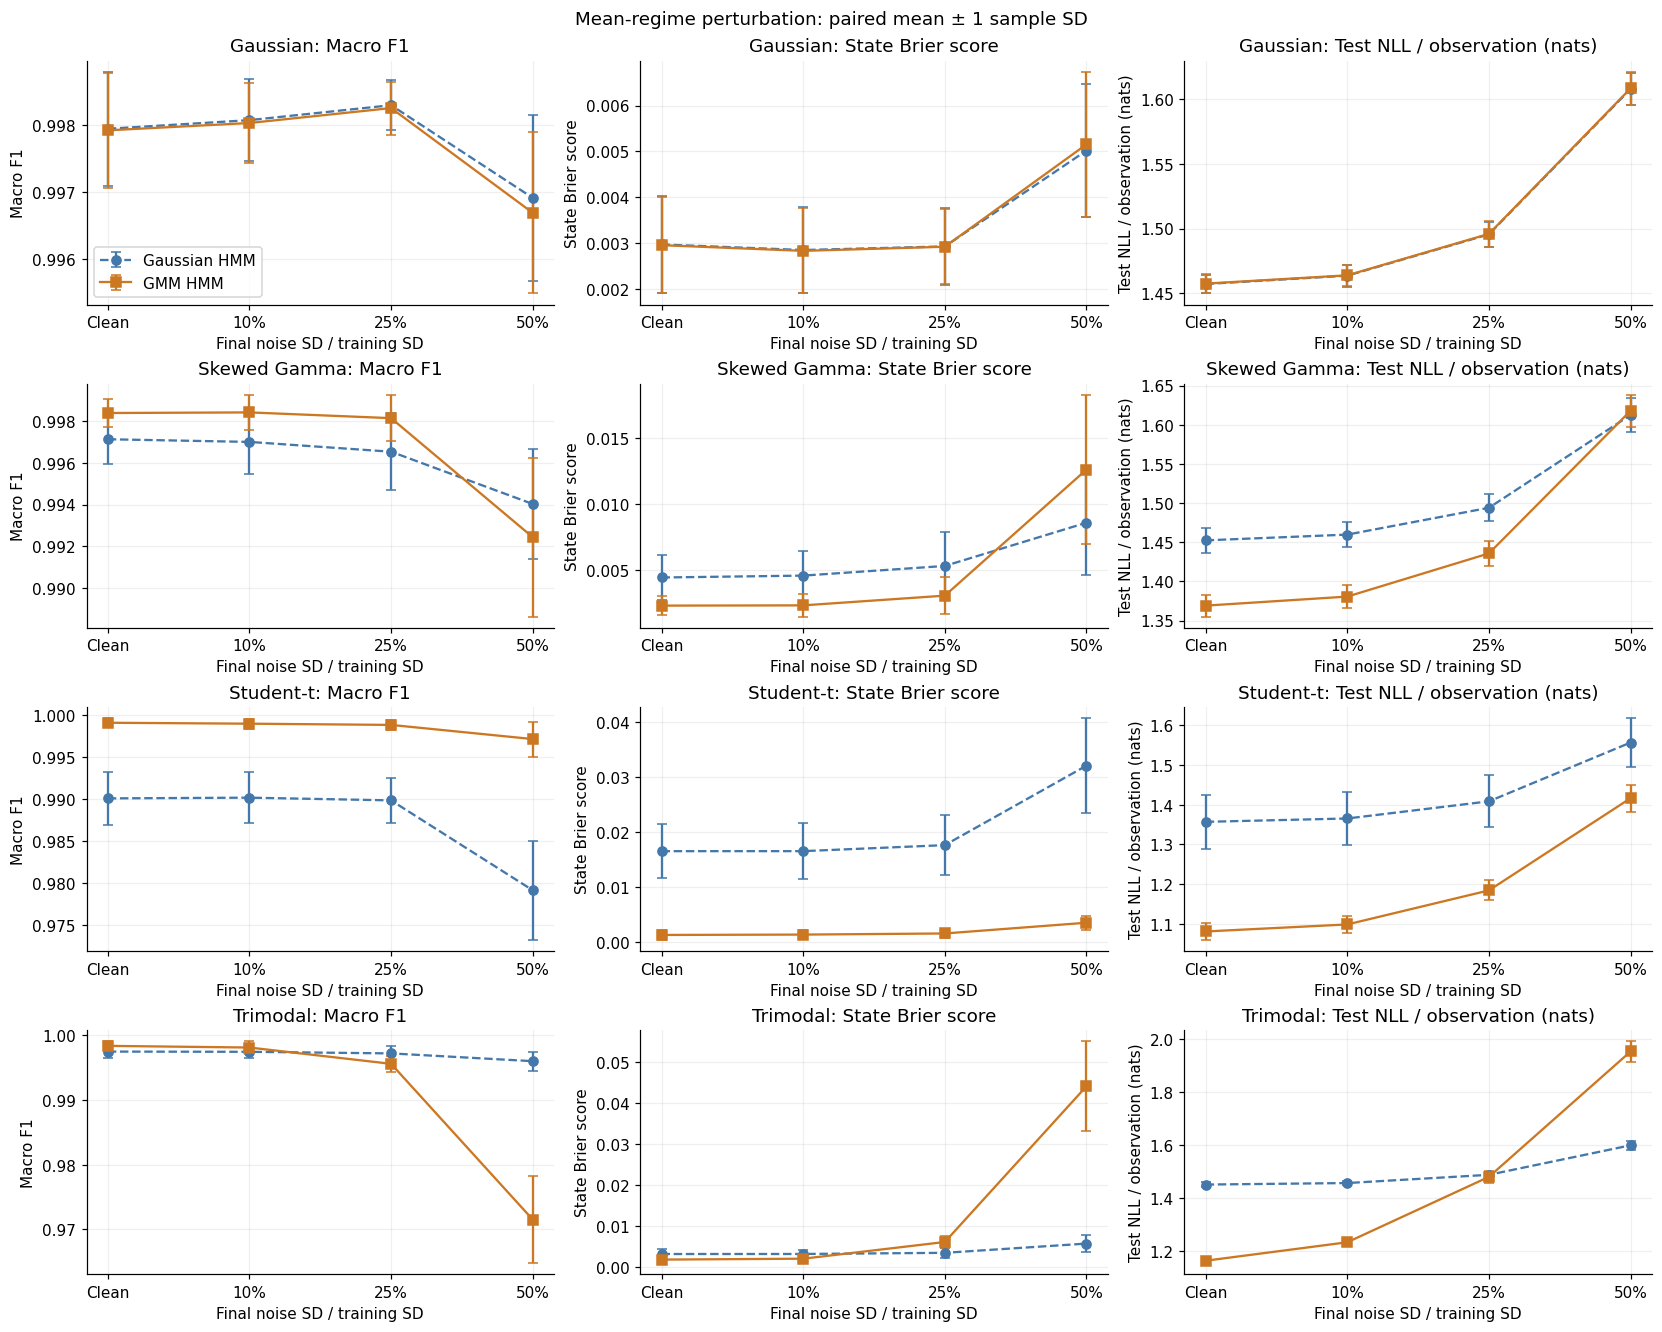

Saved perturbation outputs to /Users/leoyang/Desktop/School/CSCD94/data/synthetic/gmm_synthetic_experiments/20261024T212804Z-4r1by0vo/mean_regime_perturbation


In [19]:
mean_noise_plot_metrics = [
    ("f1_macro", "Macro F1"),
    ("state_brier_score", "State Brier score"),
    ("test_nll", "Test NLL / observation (nats)"),
]
mean_noise_families = list(mean_noise_paired.family.unique())
fig, axes = plt.subplots(
    len(mean_noise_families), len(mean_noise_plot_metrics),
    figsize=(15, 3 * len(mean_noise_families)), squeeze=False,
    layout="constrained",
)
for row, family in enumerate(mean_noise_families):
    for column, (metric, label) in enumerate(mean_noise_plot_metrics):
        ax = axes[row, column]
        for model in mean_reference.MODEL_NAMES:
            part = mean_noise_paired[
                (mean_noise_paired.family == family)
                & (mean_noise_paired.model == model)
                & (mean_noise_paired.n_train == max(mean_noise_config.train_sizes))
            ]
            summary = part.groupby("condition")[metric].agg(["mean", "std"])
            summary = summary.reindex(mean_noise_conditions)
            marker, linestyle = mean_reference.MODEL_STYLES[model]
            ax.errorbar(
                np.arange(len(mean_noise_conditions)), summary["mean"],
                yerr=summary["std"], marker=marker, linestyle=linestyle,
                color=mean_reference.MODEL_COLORS[model], capsize=3, label=model,
            )
        ax.set_xticks(range(len(mean_noise_conditions)), ["Clean", "10%", "25%", "50%"])
        ax.set(title=f"{family}: {label}", xlabel="Final noise SD / training SD")
        ax.set_ylabel(label)
        ax.grid(alpha=0.2)
axes[0, 0].legend()
fig.suptitle("Mean-regime perturbation: paired mean ± 1 sample SD")
fig.savefig(mean_noise_output / "robustness.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Saved perturbation outputs to {mean_noise_output}")


## Volatility-defined regimes with self-transition probability 0.90

This section is independent of the persistent mean-separated experiment above and can be run on its own in a fresh kernel. Run its setup, generation, and fitting cells in order, then its summaries and figures. Settings match the earlier experiment: 20,000 training observations, 5,000 independent test observations, seed 42, 10 replications, 10 starts, 1,000 maximum EM updates, four emission families, and no wide trimodal. Here the generating self-transition probability is 0.90. Use the original Markov-state generator, equal state means $(0,0,0)$, and standard deviations set by `VP90_CONFIG.state_stds` ($(1,2,4)$, i.e. variances $(1,4,16)$).

$$
A=\begin{pmatrix}p&(1-p)/2&(1-p)/2\\(1-p)/2&p&(1-p)/2\\(1-p)/2&(1-p)/2&p\end{pmatrix},\qquad \pi=(1/3,1/3,1/3).
$$

With $p=$ `VP90_CONFIG.self_transition` (0.90), expected regime duration is $1/(1-p)=10$ observations, with variable durations and no forced minimum. Labels 0/1/2 mean low/medium/high volatility. Persistent state-dependent variance creates volatility clustering.

Each state's original distribution is centered and scaled using population moments to reach mean zero and its prescribed standard deviation. 

### Measurement-noise design

Fit both HMMs on clean training data. Choose each winning start by clean-training likelihood and freeze its training-label alignment. Evaluate that exact model on the clean test sequence and on:

$$
X_t^{(\lambda)}=X_t+\lambda s_{train}\frac{t}{T-1}\eta_t,\qquad \eta_t\sim N(0,1),\qquad t=0,\ldots,T-1.
$$

The noise standard deviation starts at **zero** and rises linearly to **10%, 25%, or 50% of the training standard deviation** at the last test observation, according to `noise_levels`. The schedule spans the full test sequence. Saved variants include both `noise` and its time-varying `noise_std`; results report `noise_std_end` and `noise_std_rms`.

Here $s_{train}$ is the pooled standard deviation of that training prefix. Noise is independent of returns and labels; a shared standard-normal vector across severities makes stronger perturbations nested. Both models receive identical noisy observations. Labels and observation order remain unchanged.

Classification, state posterior scores, NLL, and switch metrics compare clean and noisy test observations against the same true labels. Exact emission KL and parameter RMSE still describe recovery of the clean generating model and stay unchanged across noise levels.

Outputs are saved in a new run under `data/synthetic/volatility_markov_experiments`. The manifest records self-transition probability 0.90. Variables use the `vp90_` prefix and do not replace the mean-regime results above. The volatility helper uses its own seed namespaces, so its latent paths differ from the mean-regime paths.


In [24]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

vp90_project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src/synthetic_data_generation").is_dir()
)
for vp90_path in (vp90_project_root / "src", vp90_project_root / "notebooks"):
    if str(vp90_path) not in sys.path:
        sys.path.insert(0, str(vp90_path))

import volatility_markov_comparison as vp90

vp90 = importlib.reload(vp90)
VP90_CONFIG = vp90.VolatilityConfig(
    master_seed=42, train_sizes=(20_000,), n_test=5_000,
    n_replicates=10, n_starts=10, max_iter=1000, n_components=3,
    state_stds=(1.0, 2.0, 4.0), self_transition=0.90,
    noise_levels=(0.10, 0.25, 0.50),  # Final ramp strengths.
    include_wide=False,
    n_density=10_000, tol_per_observation=1e-6, min_variance=1e-6,
    bootstrap_samples=2_000,
)
vp90_conditions = ["clean"] + [f"noise_{level:g}" for level in VP90_CONFIG.noise_levels]
vp90_attempt_count = (len(VP90_CONFIG.families) * len(VP90_CONFIG.train_sizes)
                    * VP90_CONFIG.n_replicates * VP90_CONFIG.n_starts * 2)
print(f"{vp90_attempt_count:,} fitting attempts; test noise does not add fitting attempts")
display(pd.DataFrame({"state": [0, 1, 2], "mean": [0.0] * 3,
                      "std": VP90_CONFIG.state_stds,
                      "variance": np.asarray(VP90_CONFIG.state_stds) ** 2}))


800 fitting attempts; test noise does not add fitting attempts


,state,mean,std,variance
0,0,0.0,1.0,1.0
1,1,0.0,2.0,4.0
2,2,0.0,4.0,16.0


### Generate shared paths and inspect regime coverage

,family,replicate,split,n,state,visits,episodes,mean_episode_length,min_episode_length,max_episode_length,switches
0,Gaussian,0,train,20000,0,7272,661,11.001513,1,95,1979
1,Gaussian,0,train,20000,1,6427,662,9.708459,1,77,1979
2,Gaussian,0,train,20000,2,6301,657,9.590563,1,56,1979
3,Gaussian,0,test,5000,0,1863,172,10.831395,1,56,491
4,Gaussian,0,test,5000,1,1520,156,9.743590,1,50,491
5,Gaussian,0,test,5000,2,1617,164,9.859756,1,41,491
24,Gaussian,1,train,20000,0,6326,656,9.643293,1,63,1981
25,Gaussian,1,train,20000,1,6986,684,10.213450,1,76,1981
26,Gaussian,1,train,20000,2,6688,642,10.417445,1,71,1981
27,Gaussian,1,test,5000,0,1862,154,12.090909,1,70,479


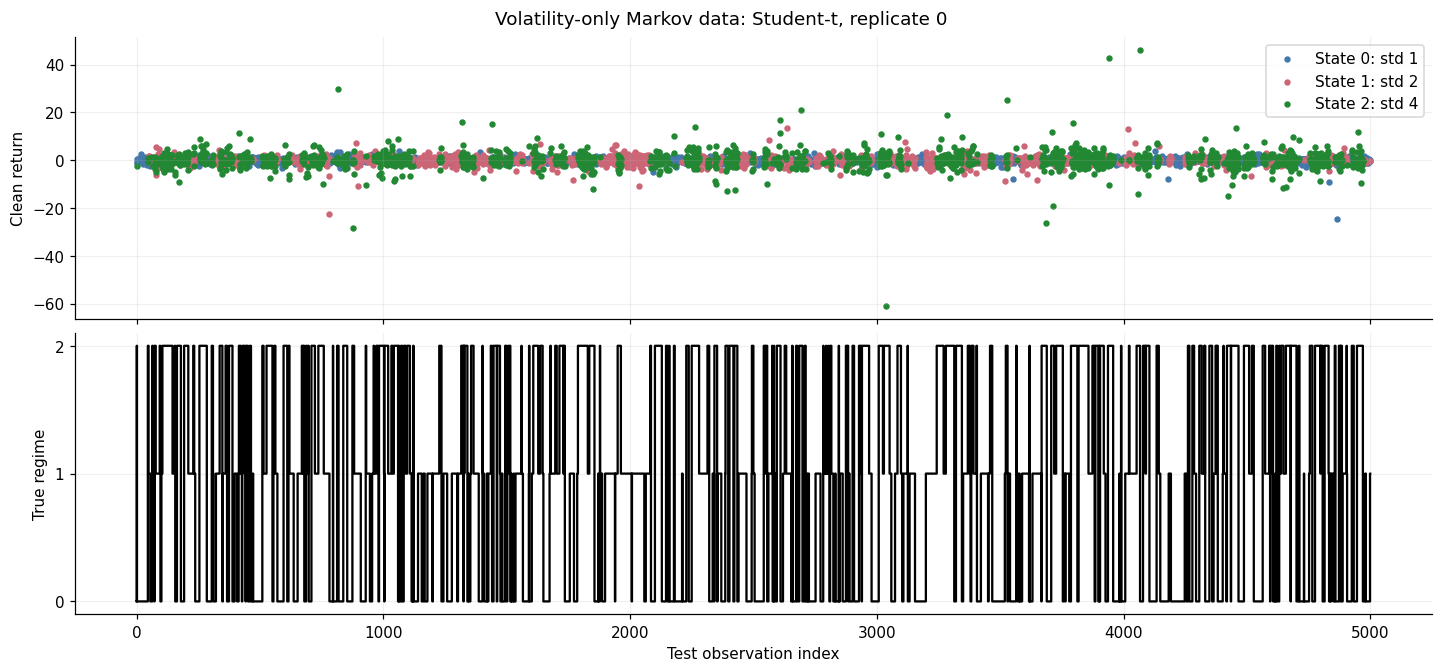

In [25]:
vp90_datasets, vp90_coverage = vp90.generate_datasets(VP90_CONFIG)
display(vp90_coverage[vp90_coverage.family == "Gaussian"])

vp90_example_family = "Student-t"
vp90_frame = vp90_datasets[0, vp90_example_family]["test"]
vp90_positions = np.arange(len(vp90_frame))
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True,
                         layout="constrained")
for state, color in enumerate(["#4477AA", "#CC6677", "#228833"]):
    mask = vp90_frame.state.to_numpy() == state
    axes[0].scatter(vp90_positions[mask], vp90_frame.x.to_numpy()[mask],
                    s=10, color=color, label=f"State {state}: std {VP90_CONFIG.state_stds[state]:g}")
axes[0].set_ylabel("Clean return")
axes[0].legend()
axes[1].step(vp90_positions, vp90_frame.state, where="mid", color="black")
axes[1].set(xlabel="Test observation index", ylabel="True regime", yticks=[0, 1, 2])
fig.suptitle(f"Volatility-only Markov data: {vp90_example_family}, replicate 0")
plt.show()


### Train the models

In [26]:
vp90_run = vp90.run_experiment(VP90_CONFIG, vp90_datasets)
vp90_run_dir = vp90.save_artifacts(
    vp90_project_root, VP90_CONFIG, vp90_datasets, vp90_coverage, vp90_run
)
vp90_results = vp90_run["results"]
vp90_paired, vp90_changes, vp90_intervals = vp90.paired_comparisons(VP90_CONFIG, vp90_results)
print(f"Saved volatility experiment artifacts to {vp90_run_dir}")
vp90_expected = pd.MultiIndex.from_product(
    [VP90_CONFIG.families, VP90_CONFIG.train_sizes,
     vp90.reference.MODEL_NAMES, vp90_conditions],
    names=["family", "n_train", "model", "condition"],
)
vp90_status = vp90_results.assign(ok=vp90_results.evaluation_status.eq("ok")).groupby(
    ["family", "n_train", "model", "condition"]
).agg(evaluations=("ok", "size"), successful=("ok", "sum"))
vp90_pair_counts = vp90_paired.groupby(
    ["family", "n_train", "model", "condition"]
).size().rename("complete_pairs")
vp90_status = vp90_status.reindex(vp90_expected).join(vp90_pair_counts).fillna(0)
display(vp90_status.astype(int))
vp90_status.to_csv(vp90_run_dir / "comparison_coverage.csv")
vp90_failures = vp90_results[vp90_results.evaluation_status != "ok"]
if not vp90_failures.empty:
    display(vp90_failures)
vp90_fit_diagnostics = vp90_run["attempts"].assign(
    failed=vp90_run["attempts"].status.ne("ok")
).groupby(["family", "n_train", "model"]).agg(
    starts=("status", "size"), failures=("failed", "sum"),
    converged_starts=("converged", "sum"), total_fit_seconds=("fit_seconds", "sum"),
)
display(vp90_fit_diagnostics)
vp90_fit_diagnostics.to_csv(vp90_run_dir / "fit_diagnostics.csv")
if vp90_paired.empty:
    raise RuntimeError(f"No complete model/condition pairs; inspect {vp90_run_dir}")

# Record this notebook as the source of the 0.90-persistence experiment.
import hashlib
import json
import shutil

vp90_notebook_source = (
    vp90_project_root / "notebooks/synthetic_persistence_experiment.ipynb"
)
vp90_manifest_path = vp90_run_dir / "manifest.json"
vp90_manifest = json.loads(vp90_manifest_path.read_text())
vp90_manifest["experiment"] = "Volatility-defined regimes with persistence 0.90"
vp90_manifest["source_hashes"][str(
    vp90_notebook_source.relative_to(vp90_project_root)
)] = hashlib.sha256(vp90_notebook_source.read_bytes()).hexdigest()
vp90_manifest_path.write_text(
    json.dumps(vp90_manifest, indent=2, allow_nan=False) + "\n"
)
shutil.copy2(vp90_notebook_source, vp90_run_dir / vp90_notebook_source.name)


Gaussian | N=20,000 | rep=0 | Gaussian HMM
Gaussian | N=20,000 | rep=0 | GMM HMM
Gaussian | N=20,000 | rep=1 | Gaussian HMM
Gaussian | N=20,000 | rep=1 | GMM HMM
Gaussian | N=20,000 | rep=2 | Gaussian HMM
Gaussian | N=20,000 | rep=2 | GMM HMM
Gaussian | N=20,000 | rep=3 | Gaussian HMM
Gaussian | N=20,000 | rep=3 | GMM HMM
Gaussian | N=20,000 | rep=4 | Gaussian HMM
Gaussian | N=20,000 | rep=4 | GMM HMM
Gaussian | N=20,000 | rep=5 | Gaussian HMM
Gaussian | N=20,000 | rep=5 | GMM HMM
Gaussian | N=20,000 | rep=6 | Gaussian HMM
Gaussian | N=20,000 | rep=6 | GMM HMM
Gaussian | N=20,000 | rep=7 | Gaussian HMM
Gaussian | N=20,000 | rep=7 | GMM HMM
Gaussian | N=20,000 | rep=8 | Gaussian HMM
Gaussian | N=20,000 | rep=8 | GMM HMM
Gaussian | N=20,000 | rep=9 | Gaussian HMM
Gaussian | N=20,000 | rep=9 | GMM HMM
Student-t | N=20,000 | rep=0 | Gaussian HMM
Student-t | N=20,000 | rep=0 | GMM HMM
Student-t | N=20,000 | rep=1 | Gaussian HMM
Student-t | N=20,000 | rep=1 | GMM HMM
Student-t | N=20,000 | r

evaluations  successful  \
family       n_train model        condition                             
Gaussian     20000   Gaussian HMM clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   
                     GMM HMM      clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   
Student-t    20000   Gaussian HMM clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   
                     GMM HMM      clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   
Trimodal     20000   Gaussian HMM clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   
                     GMM HMM      clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   
Skewed Gamma 20000   Gaussian HMM clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   
                     GMM HMM      clean                10          10   
                                  noise_0.1            10          10   
                                  noise_0.25           10          10   
                                  noise_0.5            10          10   

                                              complete_pairs  
family       n_train model        condition                   
Gaussian     20000   Gaussian HMM clean                   10  
                                  noise_0.1               10  
                                  noise_0.25              10  
                                  noise_0.5               10  
                     GMM HMM      clean                   10  
                                  noise_0.1               10  
                                  noise_0.25              10  
                                  noise_0.5               10  
Student-t    20000   Gaussian HMM clean                   10  
                                  noise_0.1               10  
                                  noise_0.25              10  
                                  noise_0.5               10  
                     GMM HMM      clean                   10  
                                  noise_0.1               10  
                                  noise_0.25              10  
                                  noise_0.5               10  
Trimodal     20000   Gaussian HMM clean                   10  
                                  noise_0.1               10  
                                  noise_0.25              10  
                                  noise_0.5               10  
                     GMM HMM      clean                   10  
                                  noise_0.1               10  
                                  noise_0.25       

starts  failures  converged_starts  \
family       n_train model                                              
Gaussian     20000   GMM HMM          100         0               100   
                     Gaussian HMM     100         0               100   
Skewed Gamma 20000   GMM HMM          100         0               100   
                     Gaussian HMM     100         0               100   
Student-t    20000   GMM HMM          100         0                96   
                     Gaussian HMM     100         0               100   
Trimodal     20000   GMM HMM          100         0               100   
                     Gaussian HMM     100         0               100   

                                   total_fit_seconds  
family       n_train model                            
Gaussian     20000   GMM HMM             4077.478004  
                     Gaussian HMM        3072.125688  
Skewed Gamma 20000   GMM HMM             7469.341217  
                     Gaussian HMM        3285.821640  
Student-t    20000   GMM HMM            13912.693344  
                     Gaussian HMM        1419.129394  
Trimodal     20000   GMM HMM             3763.178102  
                     Gaussian HMM        1362.175692

PosixPath('/Users/leoyang/Desktop/School/CSCD94/data/synthetic/volatility_markov_experiments/20261025T103033Z-48jhkzmt/synthetic_persistence_experiment.ipynb')

### Clean and noisy test scores

In [27]:
vp90_summary = vp90_paired.groupby(
    ["family", "n_train", "model", "condition"]
)[vp90.SCORE_METRICS + ["fit_seconds", "total_fit_seconds"]].agg(["mean", "std", "count"])
vp90_summary.to_csv(vp90_run_dir / "metric_summary.csv")
vp90_display_metrics = [
    "aligned_accuracy", "f1_macro", "balanced_accuracy", "mcc",
    "test_nll", "state_log_loss", "state_brier_score",
    "mean_true_state_posterior", "true_switches", "inferred_switches",
    "absolute_switch_count_error",
]
display(vp90_paired.groupby(["family", "n_train", "model", "condition"])[
    vp90_display_metrics
].mean().round(4))
vp90_clean_parameters = vp90_paired[vp90_paired.condition == "clean"].groupby(
    ["family", "n_train", "model"]
)[["emission_kl", "transition_rmse", "mean_rmse", "variance_rmse"]].mean()
display(vp90_clean_parameters.round(4))
vp90_clean_parameters.to_csv(vp90_run_dir / "clean_parameter_recovery.csv")


aligned_accuracy  f1_macro  \
family       n_train model        condition                                
Gaussian     20000   GMM HMM      clean                 0.7432    0.7426   
                                  noise_0.1             0.7390    0.7386   
                                  noise_0.25            0.7262    0.7270   
                                  noise_0.5             0.6728    0.6736   
                     Gaussian HMM clean                 0.7462    0.7457   
                                  noise_0.1             0.7420    0.7417   
                                  noise_0.25            0.7293    0.7301   
                                  noise_0.5             0.6740    0.6743   
Skewed Gamma 20000   GMM HMM      clean                 0.7806    0.7798   
                                  noise_0.1             0.7783    0.7780   
                                  noise_0.25            0.7562    0.7575   
                                  noise_0.5             0.6828    0.6833   
                     Gaussian HMM clean                 0.5722    0.4962   
                                  noise_0.1             0.5713    0.4951   
                                  noise_0.25            0.5713    0.4958   
                                  noise_0.5             0.5563    0.4865   
Student-t    20000   GMM HMM      clean                 0.6149    0.5961   
                                  noise_0.1             0.6095    0.5932   
                                  noise_0.25            0.5910    0.5819   
                                  noise_0.5             0.5280    0.5147   
                     Gaussian HMM clean                 0.5628    0.4583   
                                  noise_0.1             0.5608    0.4567   
                                  noise_0.25            0.5534    0.4510   
                                  noise_0.5             0.5057    0.4143   
Trimodal     20000   GMM HMM      clean                 0.8977    0.8973   
                                  noise_0.1             0.8870    0.8866   
                                  noise_0.25            0.8358    0.8357   
                                  noise_0.5             0.7351    0.7330   
                     Gaussian HMM clean                 0.5485    0.4875   
                                  noise_0.1             0.5483    0.4872   
                                  noise_0.25            0.5471    0.4859   
                                  noise_0.5             0.5394    0.4797   

                                              balanced_accuracy     mcc  \
family       n_train model        condition                               
Gaussian     20000   GMM HMM      clean                  0.7417  0.6160   
                                  noise_0.1              0.7376  0.6098   
                                  noise_0.25             0.7253  0.5914   
                                  noise_0.5              0.6737  0.5188   
                     Gaussian HMM clean                  0.7448  0.6202   
                                  noise_0.1              0.7407  0.6139   
                                  noise_0.25             0.7285  0.5960   
                                  noise_0.5              0.6750  0.5215   
Skewed Gamma 20000   GMM HMM      clean                  0.7792  0.6714   
                                  noise_0.1              0.7771  0.6680   
                                  noise_0.25             0.7560  0.6364   
                                  noise_0.5              0.6847  0.5362   
                     Gaussian HMM clean                  0.5658  0.3898   
                                  noise_0.1              0.5648  0.3882   
                                  noise_0.25             0.5649  0.3867   
                                  noise_0.5              0.5506  0.3583   
Student-t    20000   GMM HMM      clean                  0.6116  0.4366   
                                  no

emission_kl  transition_rmse  mean_rmse  \
family       n_train model                                                   
Gaussian     20000   GMM HMM            0.0009           0.0090     0.0331   
                     Gaussian HMM       0.0003           0.0086     0.0323   
Skewed Gamma 20000   GMM HMM            0.0089           0.0072     0.0369   
                     Gaussian HMM       0.4717           0.3157     1.9824   
Student-t    20000   GMM HMM            0.0453           0.0533     0.0351   
                     Gaussian HMM       1.1244           0.3824     0.1995   
Trimodal     20000   GMM HMM            0.0058           0.0043     0.0306   
                     Gaussian HMM       3.6296           0.3059     2.6101   

                                   variance_rmse  
family       n_train model                        
Gaussian     20000   GMM HMM              0.2131  
                     Gaussian HMM         0.1382  
Skewed Gamma 20000   GMM HMM              0.3988  
                     Gaussian HMM         9.2845  
Student-t    20000   GMM HMM              3.1479  
                     Gaussian HMM        64.2424  
Trimodal     20000   GMM HMM              0.1203  
                     Gaussian HMM         5.1895

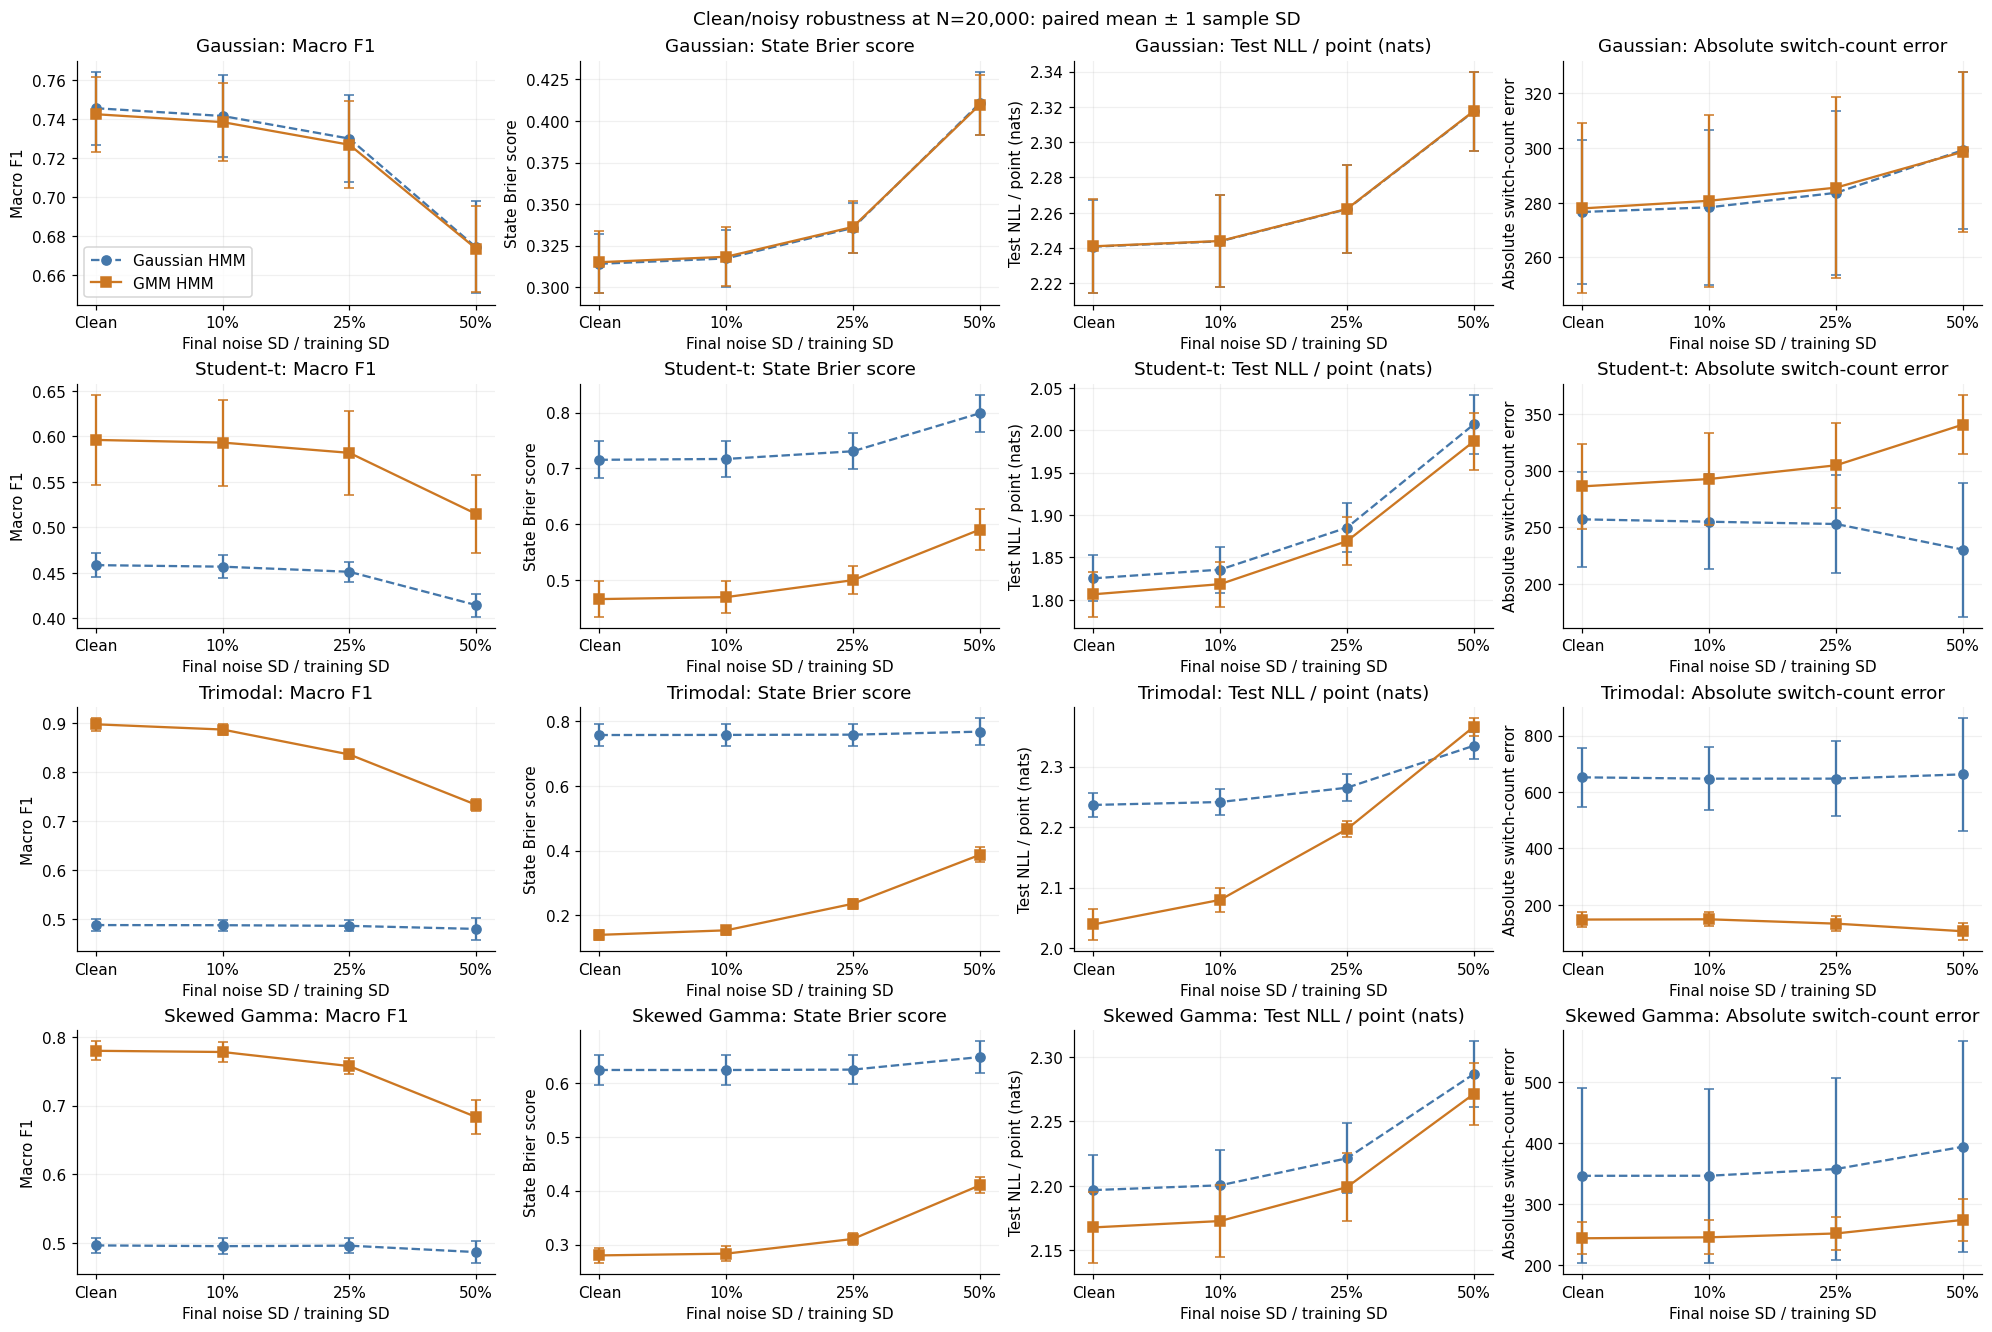

In [28]:
vp90_plot_size = max(VP90_CONFIG.train_sizes)
vp90_plot_metrics = [
    ("f1_macro", "Macro F1"),
    ("state_brier_score", "State Brier score"),
    ("test_nll", "Test NLL / point (nats)"),
    ("absolute_switch_count_error", "Absolute switch-count error"),
]
fig, axes = plt.subplots(len(VP90_CONFIG.families), len(vp90_plot_metrics),
                         figsize=(18, 3 * len(VP90_CONFIG.families)),
                         squeeze=False, layout="constrained")
for row, family in enumerate(VP90_CONFIG.families):
    for column, (metric, label) in enumerate(vp90_plot_metrics):
        ax = axes[row, column]
        for model in vp90.reference.MODEL_NAMES:
            part = vp90_paired[(vp90_paired.family == family)
                             & (vp90_paired.n_train == vp90_plot_size)
                             & (vp90_paired.model == model)]
            summary = part.groupby("condition")[metric].agg(["mean", "std"]).reindex(vp90_conditions)
            marker, linestyle = vp90.reference.MODEL_STYLES[model]
            positions = np.arange(len(vp90_conditions))
            ax.plot(positions, summary["mean"], marker=marker, linestyle=linestyle,
                    color=vp90.reference.MODEL_COLORS[model], label=model)
            ax.errorbar(positions, summary["mean"], yerr=summary["std"],
                        fmt="none", capsize=3, color=vp90.reference.MODEL_COLORS[model])
        ax.set_xticks(np.arange(len(vp90_conditions)),
                      ["Clean"] + [f"{level:.0%}" for level in VP90_CONFIG.noise_levels])
        ax.set(title=f"{family}: {label}", xlabel="Final noise SD / training SD", ylabel=label)
axes[0, 0].legend()
fig.suptitle(f"Clean/noisy robustness at N={vp90_plot_size:,}: paired mean ± 1 sample SD")
fig.savefig(vp90_run_dir / "noise_robustness.png", dpi=160, bbox_inches="tight")
plt.show()


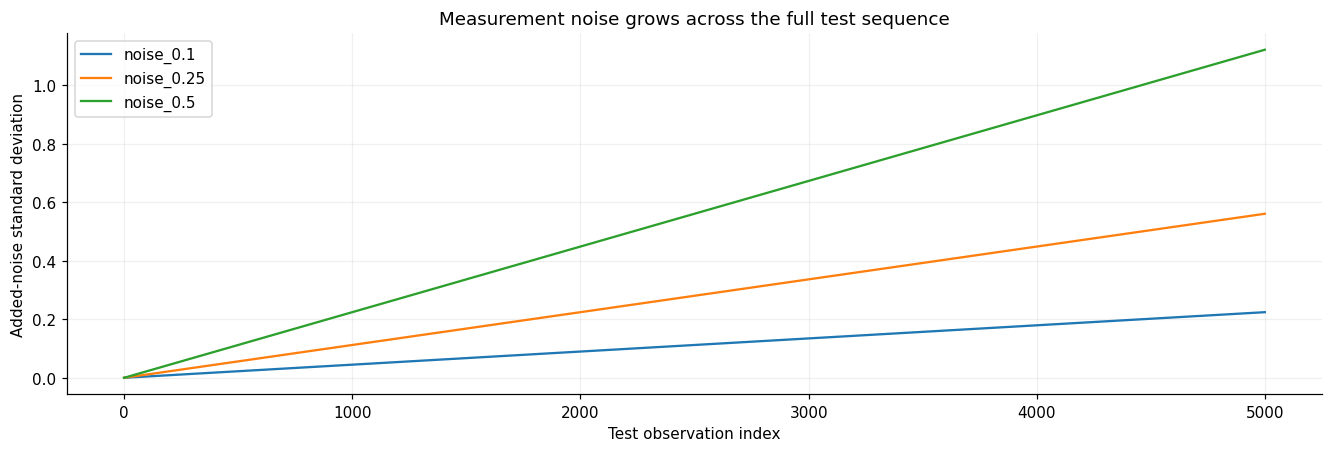

In [29]:
vp90_noise_variants = vp90_run["variants"][0, vp90_example_family, vp90_plot_size]
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
for condition in vp90_conditions[1:]:
    frame = vp90_noise_variants[condition]
    ax.plot(frame.time, frame.noise_std, label=condition)
ax.set(xlabel="Test observation index", ylabel="Added-noise standard deviation",
       title="Measurement noise grows across the full test sequence")
ax.legend()
fig.savefig(vp90_run_dir / "noise_schedule.png", dpi=160, bbox_inches="tight")
plt.show()


### Paired degradation and model differences


In [30]:
vp90_changes.to_csv(vp90_run_dir / "noisy_minus_clean_by_replicate.csv", index=False)
vp90_intervals.to_csv(vp90_run_dir / "noisy_minus_clean_intervals.csv", index=False)
display(vp90_intervals[vp90_intervals.metric.isin([
    "f1_macro", "test_nll", "state_brier_score", "absolute_switch_count_error"
])].round(5))

vp90_model_deltas = []
for condition in vp90_conditions:
    values = vp90.reference.paired_differences(
        VP90_CONFIG, vp90_paired[vp90_paired.condition == condition],
        ["f1_macro", "test_nll", "state_brier_score", "absolute_switch_count_error"],
    )
    values["condition"] = condition
    vp90_model_deltas.append(values)
vp90_model_deltas = pd.concat(vp90_model_deltas, ignore_index=True)
vp90_model_deltas.to_csv(vp90_run_dir / "gmm_minus_gaussian_by_condition.csv", index=False)
display(vp90_model_deltas.round(5))


,family,n_train,model,condition,metric,n_pairs,mean_delta,ci_low,ci_high
3,Gaussian,20000,GMM HMM,noise_0.1,f1_macro,10,-0.00405,-0.00884,0.00010
17,Gaussian,20000,GMM HMM,noise_0.1,state_brier_score,10,0.00326,0.00125,0.00503
20,Gaussian,20000,GMM HMM,noise_0.1,test_nll,10,0.00301,0.00214,0.00387
25,Gaussian,20000,GMM HMM,noise_0.1,absolute_switch_count_error,10,2.80000,0.30000,5.00000
29,Gaussian,20000,GMM HMM,noise_0.25,f1_macro,10,-0.01566,-0.02166,-0.00975
...,...,...,...,...,...,...,...,...,...
597,Trimodal,20000,Gaussian HMM,noise_0.25,absolute_switch_count_error,10,-4.60000,-34.80500,15.60000
601,Trimodal,20000,Gaussian HMM,noise_0.5,f1_macro,10,-0.00784,-0.02409,0.00223
615,Trimodal,20000,Gaussian HMM,noise_0.5,state_brier_score,10,0.01044,-0.00170,0.03021
618,Trimodal,20000,Gaussian HMM,noise_0.5,test_nll,10,0.09775,0.09113,0.10551


,family,n_train,metric,n_pairs,mean_delta,ci_low,ci_high,condition
0,Gaussian,20000,f1_macro,10,-0.00308,-0.00751,0.00105,clean
1,Gaussian,20000,test_nll,10,0.00019,-0.00002,0.00040,clean
2,Gaussian,20000,state_brier_score,10,0.00096,-0.00024,0.00222,clean
3,Gaussian,20000,absolute_switch_count_error,10,1.30000,-6.20000,8.80250,clean
4,Skewed Gamma,20000,f1_macro,10,0.28356,0.27273,0.29293,clean
...,...,...,...,...,...,...,...,...
59,Student-t,20000,absolute_switch_count_error,10,110.30000,70.99500,151.10500,noise_0.5
60,Trimodal,20000,f1_macro,10,0.25333,0.23966,0.27019,noise_0.5
61,Trimodal,20000,test_nll,10,0.03131,0.01846,0.04277,noise_0.5
62,Trimodal,20000,state_brier_score,10,-0.38067,-0.41277,-0.34917,noise_0.5


### Confusion matrices and per-state recovery


precision  recall      f1  \
family   n_train model        condition  state                              
Gaussian 20000   GMM HMM      clean      0         0.7895  0.7857  0.7863   
                                         1         0.6455  0.6767  0.6579   
                                         2         0.8085  0.7627  0.7837   
                              noise_0.1  0         0.7910  0.7765  0.7821   
                                         1         0.6372  0.6754  0.6528   
...                                                   ...     ...     ...   
Trimodal 20000   Gaussian HMM noise_0.25 1         0.2427  0.1054  0.1465   
                                         2         0.6770  0.5607  0.5993   
                              noise_0.5  0         0.5854  0.9184  0.7014   
                                         1         0.2482  0.1079  0.1494   
                                         2         0.6393  0.5718  0.5882   

                                                support  
family   n_train model        condition  state           
Gaussian 20000   GMM HMM      clean      0       1719.5  
                                         1       1638.4  
                                         2       1642.1  
                              noise_0.1  0       1719.5  
                                         1       1638.4  
...                                                 ...  
Trimodal 20000   Gaussian HMM noise_0.25 1       1638.4  
                                         2       1642.1  
                              noise_0.5  0       1719.5  
                                         1       1638.4  
                                         2       1642.1  

[96 rows x 4 columns]

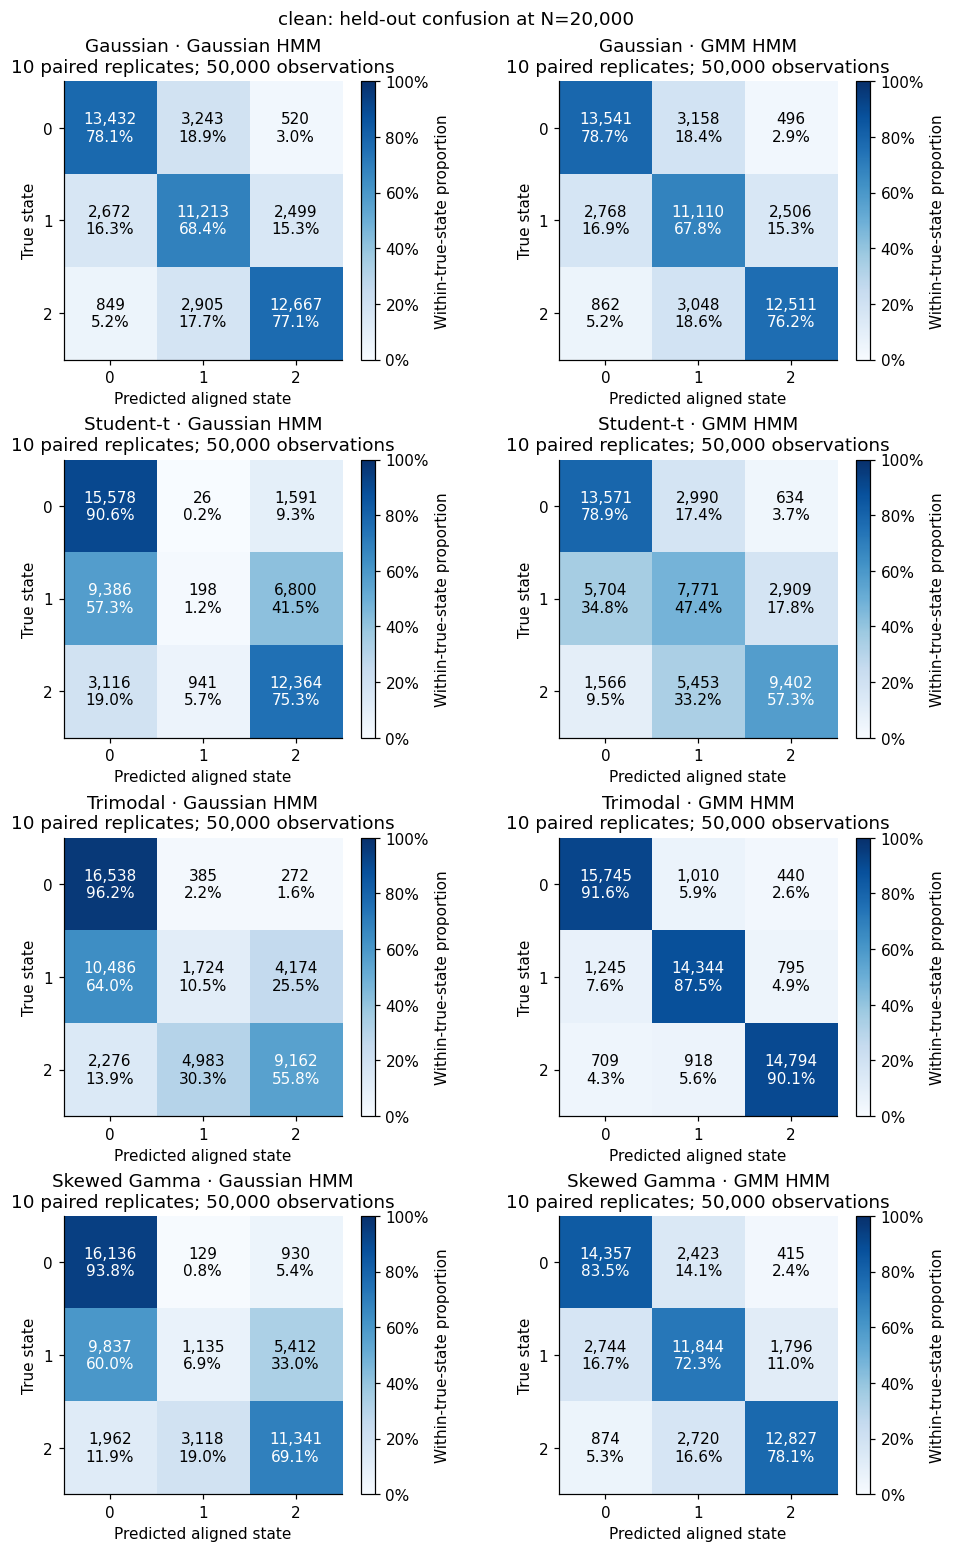

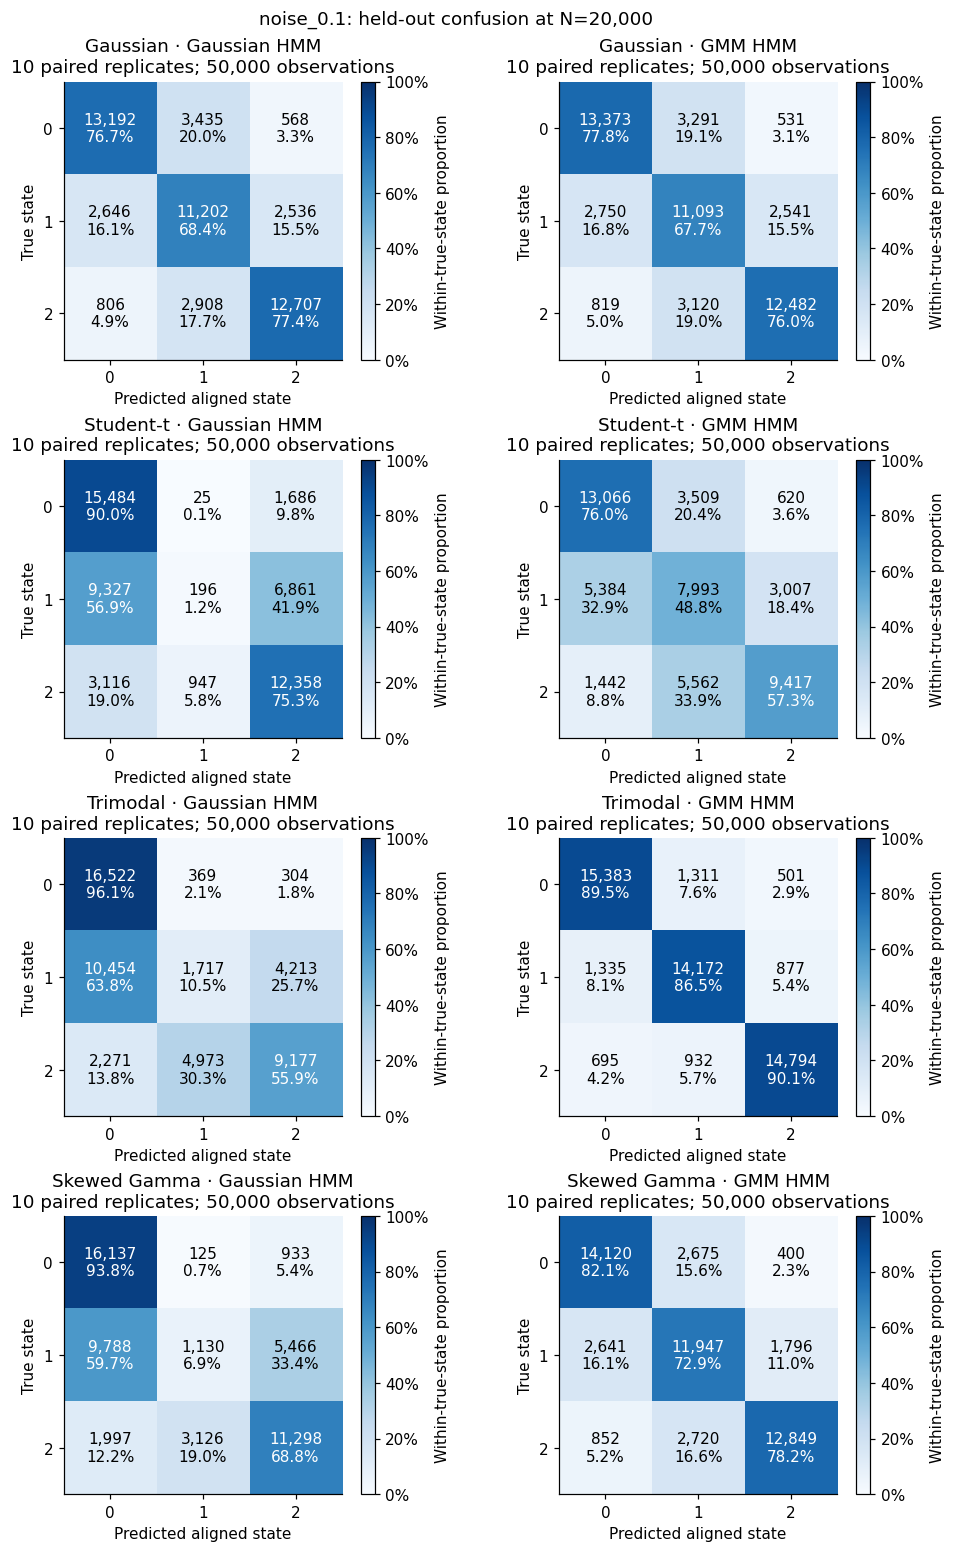

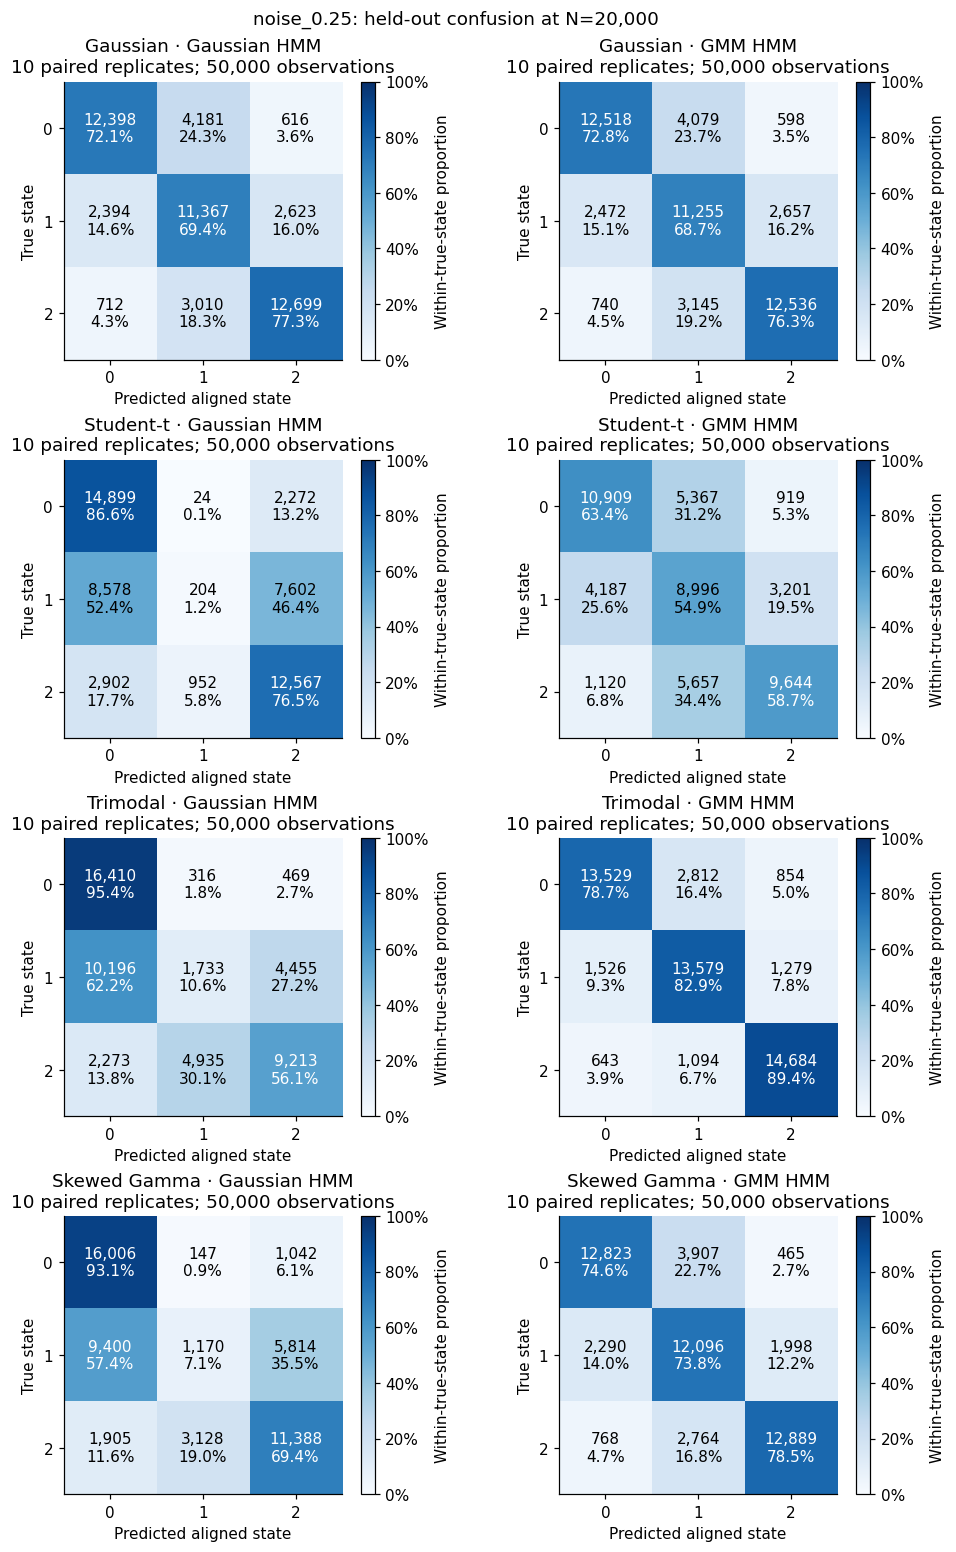

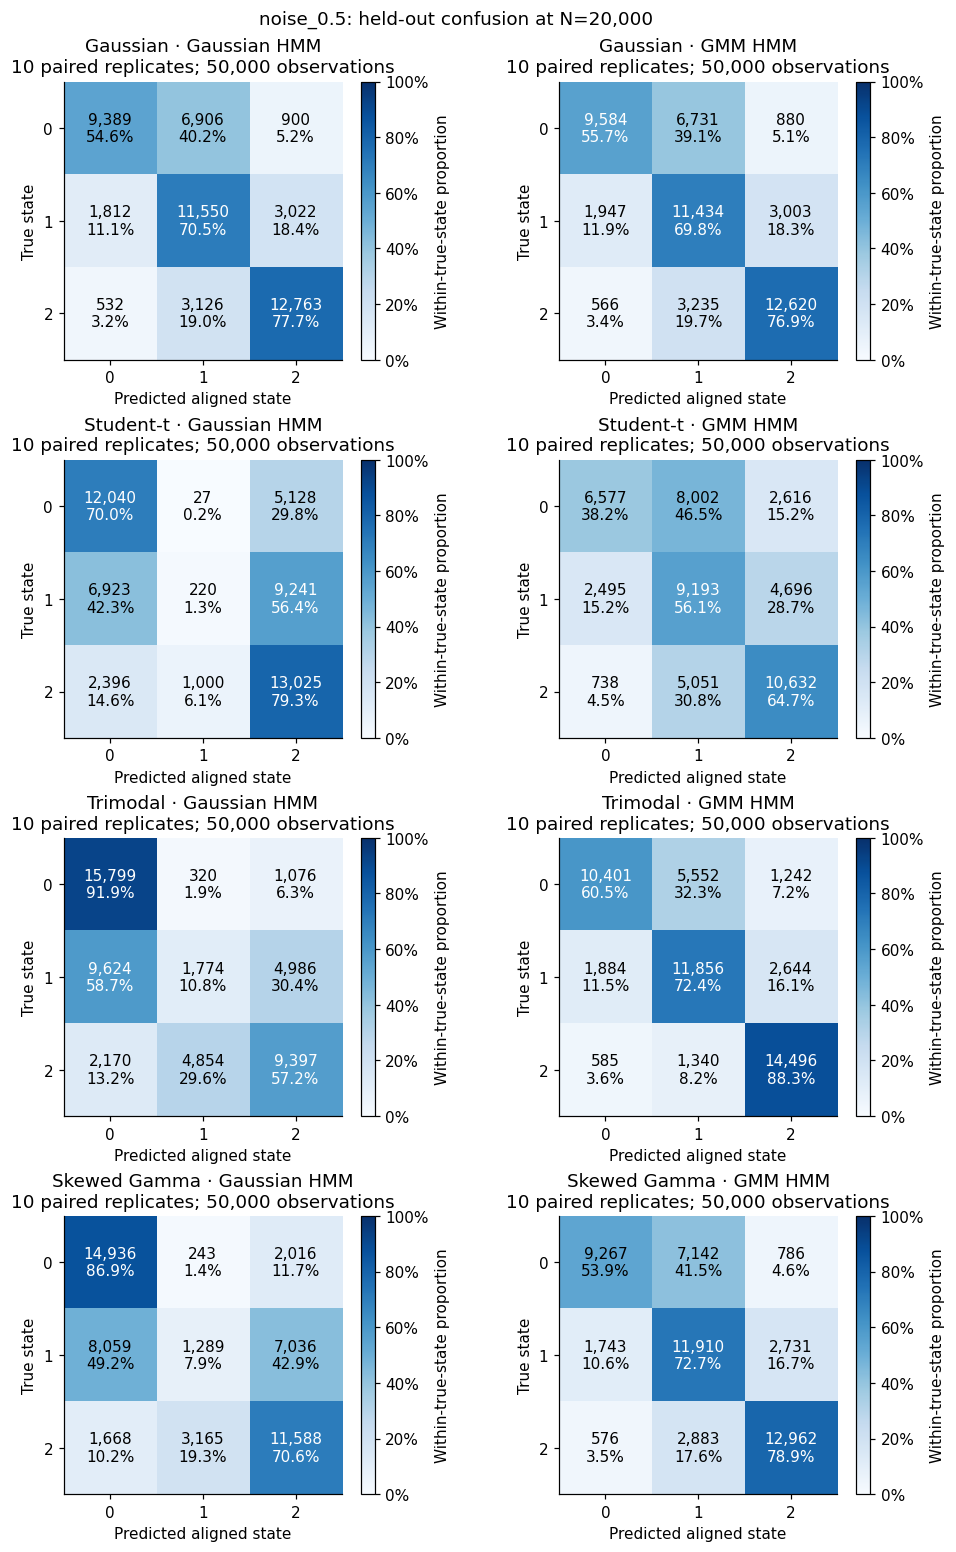

In [31]:
vp90_keys = vp90.reference.PAIR_KEYS + ["model", "condition"]
vp90_state_paired = vp90_run["per_state"].merge(
    vp90_paired[vp90_keys], on=vp90_keys, validate="many_to_one"
)
vp90_state_summary = vp90_state_paired.groupby(
    ["family", "n_train", "model", "condition", "state"]
)[["precision", "recall", "f1", "support"]].agg(["mean", "std", "count"])
vp90_state_summary.to_csv(vp90_run_dir / "per_state_summary.csv")
display(vp90_state_paired.groupby(
    ["family", "n_train", "model", "condition", "state"]
)[["precision", "recall", "f1", "support"]].mean().round(4))
for condition in vp90_conditions:
    fig = vp90.reference.plot_confusions(
        VP90_CONFIG,
        vp90_run["confusion"][vp90_run["confusion"].condition == condition],
        vp90_paired[vp90_paired.condition == condition], vp90_plot_size,
    )
    fig.suptitle(f"{condition}: held-out confusion at N={vp90_plot_size:,}")
    fig.savefig(vp90_run_dir / f"confusions_{condition}.png", dpi=160, bbox_inches="tight")
    plt.show()


### Illustrative clean versus noisy decoded paths


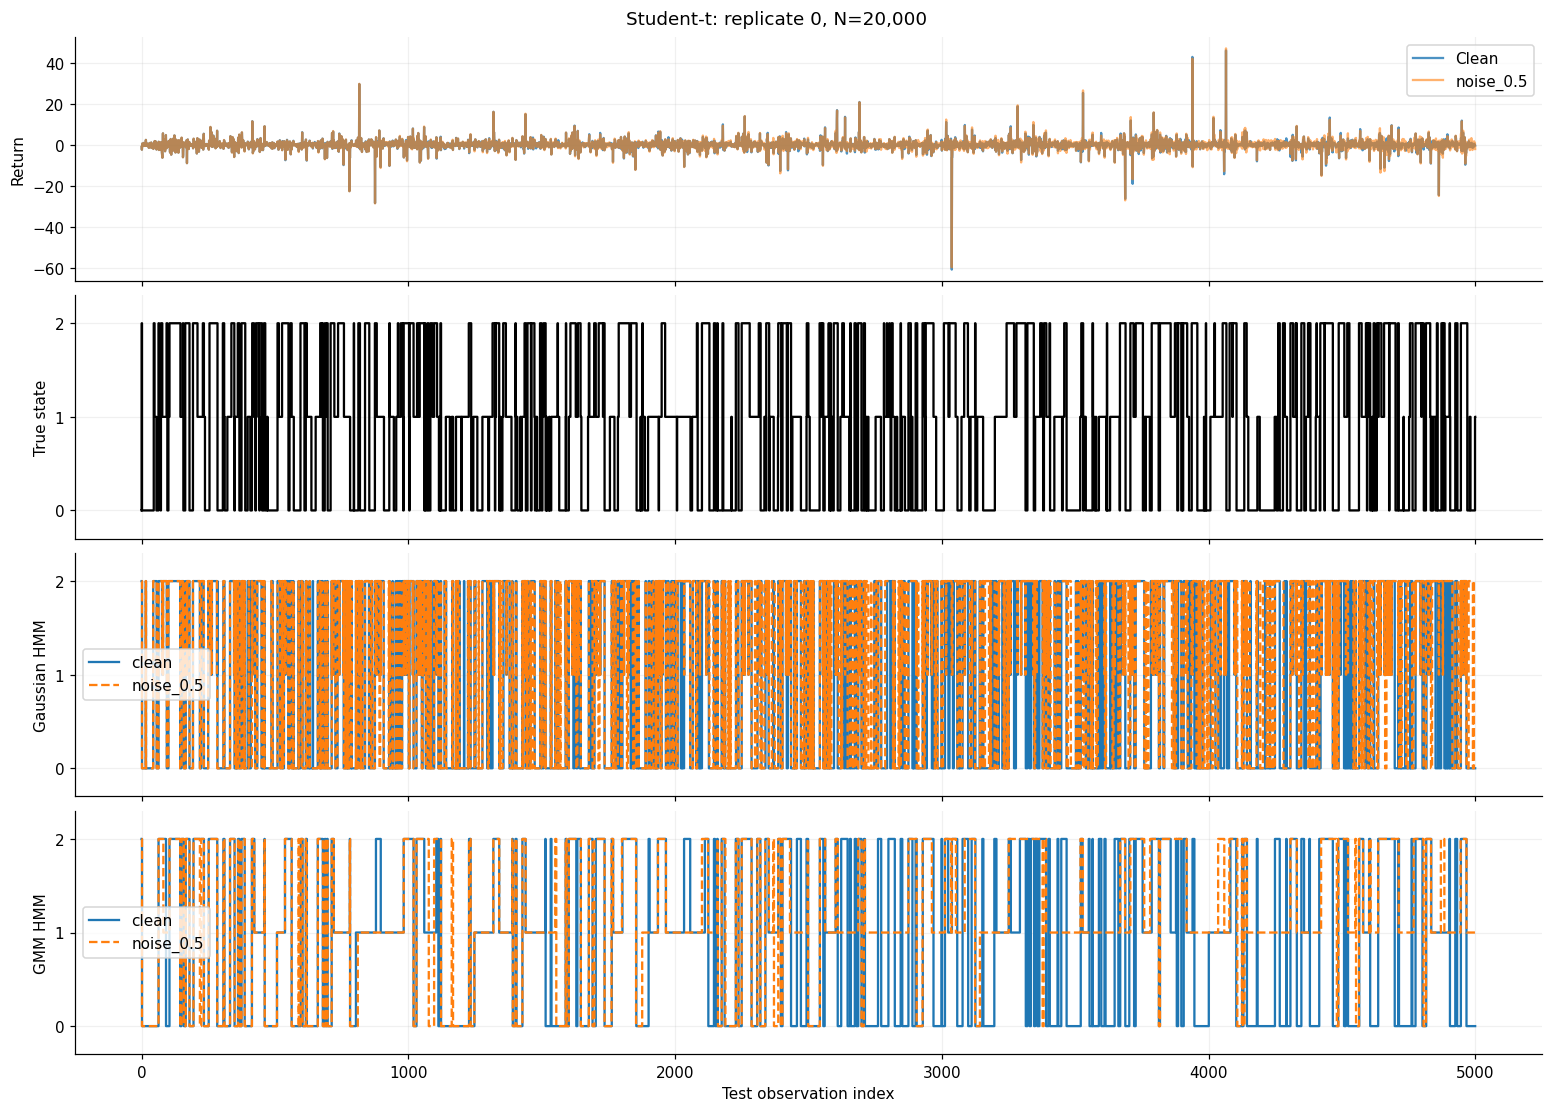

In [32]:
vp90_example_condition = vp90_conditions[-1]
vp90_example_variants = vp90_run["variants"][0, vp90_example_family, vp90_plot_size]
vp90_example_clean = vp90_example_variants["clean"]
vp90_example_noisy = vp90_example_variants[vp90_example_condition]
vp90_zoom = len(vp90_example_clean)
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True,
                         layout="constrained")
axes[0].plot(vp90_example_clean.time, vp90_example_clean.x, alpha=0.8, label="Clean")
axes[0].plot(vp90_example_noisy.time, vp90_example_noisy.x, alpha=0.6,
             label=vp90_example_condition)
axes[0].set_ylabel("Return")
axes[0].legend()
axes[1].step(np.arange(vp90_zoom), vp90_example_clean.state, where="mid", color="black")
axes[1].set_ylabel("True state")
for ax, model in zip(axes[2:], vp90.reference.MODEL_NAMES):
    for condition, linestyle in (("clean", "-"), (vp90_example_condition, "--")):
        example = vp90_run["examples"].get((vp90_example_family, model, condition))
        if example is not None:
            ax.step(np.arange(vp90_zoom), example["predicted"][:vp90_zoom],
                    where="mid", linestyle=linestyle, label=condition)
        else:
            ax.text(0.02, 0.9, f"Unavailable: {condition}", transform=ax.transAxes)
    ax.set_ylabel(model)
    ax.legend()
for ax in axes[1:]:
    ax.set(yticks=[0, 1, 2], ylim=(-0.3, 2.3))
axes[-1].set_xlabel("Test observation index")
fig.suptitle(f"{vp90_example_family}: replicate 0, N={vp90_plot_size:,}")
fig.savefig(vp90_run_dir / "clean_noisy_decoded_example.png", dpi=160, bbox_inches="tight")
plt.show()


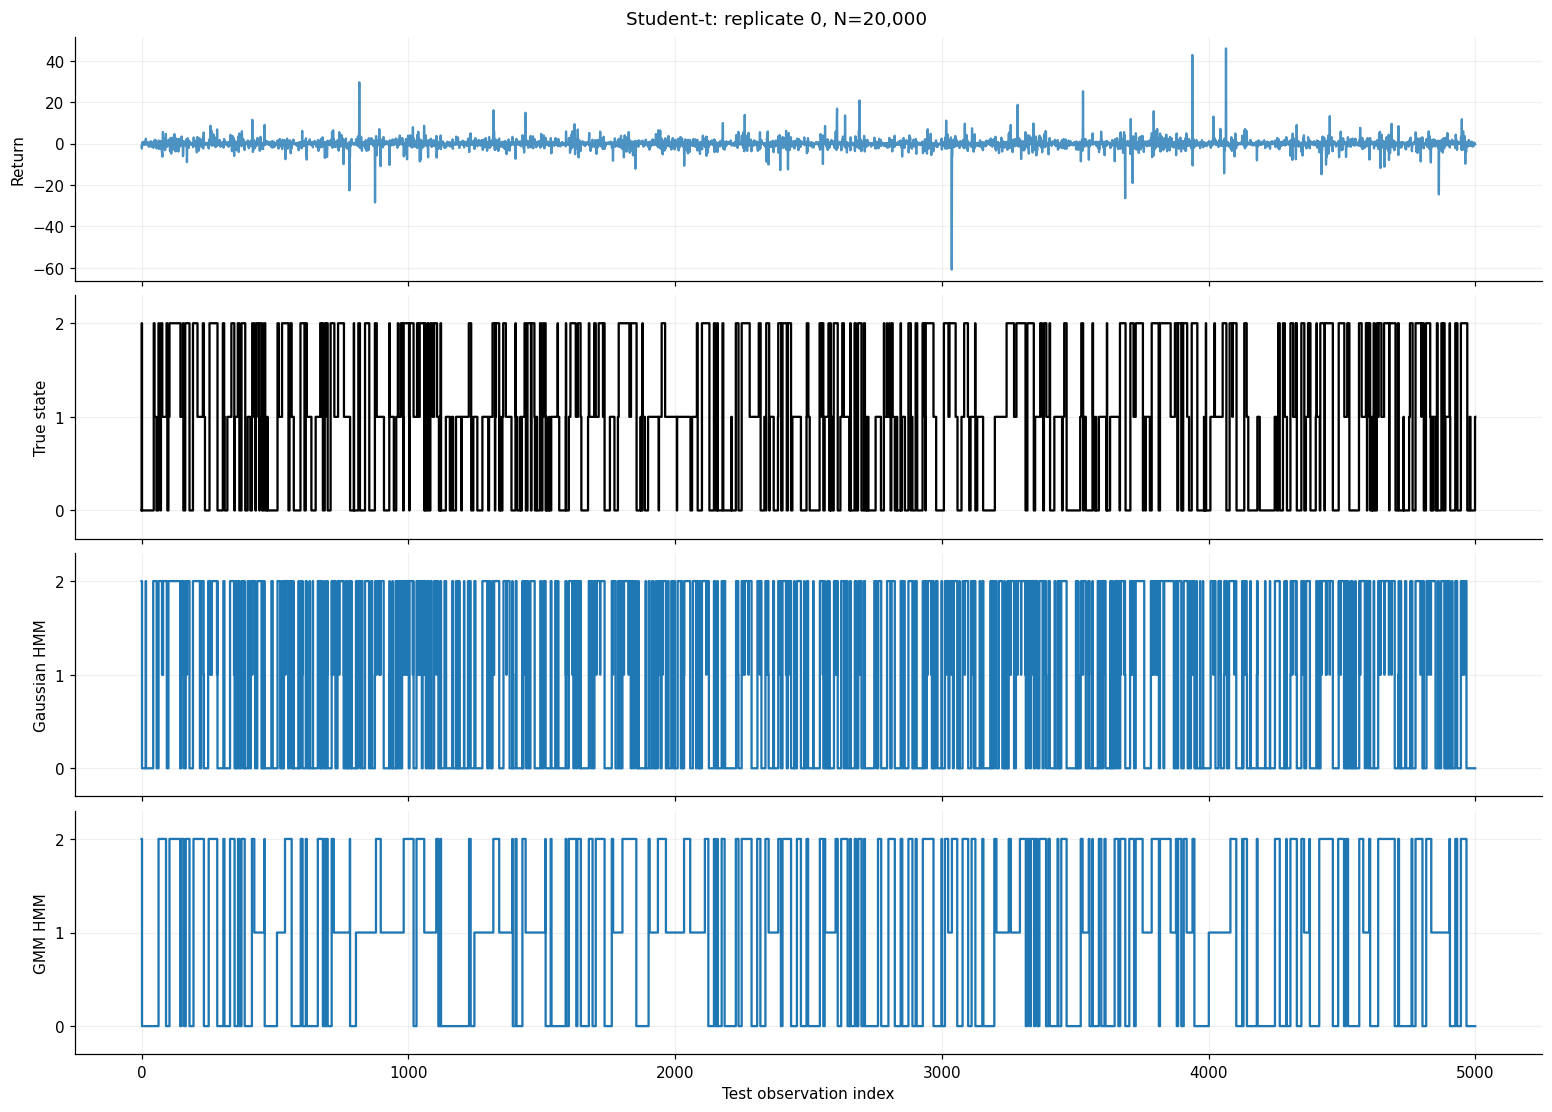

In [33]:
vp90_clean_example = vp90_run["variants"][0, vp90_example_family, vp90_plot_size]["clean"]
vp90_clean_zoom = len(vp90_clean_example)
fig, axes = plt.subplots(
    4, 1, figsize=(14, 10), sharex=True, layout="constrained"
)
axes[0].plot(
    vp90_clean_example.time, vp90_clean_example.x, alpha=0.8
)
axes[0].set_ylabel("Return")
axes[1].step(
    np.arange(vp90_clean_zoom), vp90_clean_example.state, where="mid", color="black"
)
axes[1].set_ylabel("True state")
for ax, model in zip(axes[2:], vp90.reference.MODEL_NAMES):
    example = vp90_run["examples"].get((vp90_example_family, model, "clean"))
    if example is not None:
        ax.step(
            np.arange(vp90_clean_zoom), example["predicted"][:vp90_clean_zoom],
            where="mid", linestyle="-"
        )
    else:
        ax.text(0.02, 0.9, "Unavailable: clean", transform=ax.transAxes)
    ax.set_ylabel(model)
for ax in axes[1:]:
    ax.set(yticks=[0, 1, 2], ylim=(-0.3, 2.3))
axes[-1].set_xlabel("Test observation index")
fig.suptitle(f"{vp90_example_family}: replicate 0, N={vp90_plot_size:,}")
fig.savefig(
    vp90_run_dir / "clean_decoded_example.png", dpi=160, bbox_inches="tight"
)
plt.show()


## True generating versus fitted emission distributions

In [34]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np

import synthetic_emission_comparison as density_reference


def plot_saved_emission_overlays(saved_run_dir, experiment_label, file_prefix):
    """Overlay true and fitted densities using saved training-aligned parameters.

    Use replicate zero and the largest saved training size. Read generating
    moments from the run manifest so each experiment uses its own target density.
    """
    saved_run_dir = Path(saved_run_dir)
    manifest = json.loads((saved_run_dir / "manifest.json").read_text())
    records = json.loads((saved_run_dir / "parameters.json").read_text())
    n_train = max(manifest["settings"]["train_sizes"])
    replicate = 0
    parameters = {
        (record["family"], record["model"]): record
        for record in records
        if record["replicate"] == replicate and record["n_train"] == n_train
    }
    if not parameters:
        raise ValueError("No fitted parameters for replicate 0 and selected size")
    if "stds" in manifest:
        target_means = np.asarray(manifest["means"], dtype=float)
        target_stds = np.asarray(manifest["stds"], dtype=float)
    else:
        distribution = manifest["distributions"]
        target_means = np.asarray(distribution["means"], dtype=float)
        target_stds = np.sqrt(np.broadcast_to(
            np.asarray(distribution["variance"], dtype=float), target_means.shape
        ))
    print(f"Source fits: {saved_run_dir}")
    print(f"True means: {target_means}; true standard deviations: {target_stds}")
    for family in manifest["families"]:
        original_means, original_variances = density_reference.true_moments(family)
        scales = target_stds / np.sqrt(original_variances)
        fig, axes = plt.subplots(1, len(target_means), figsize=(15, 3.8),
                                 squeeze=False, layout="constrained")
        for state, ax in enumerate(axes[0]):
            window = 4 * target_stds[state]
            grid = np.linspace(target_means[state] - window,
                               target_means[state] + window, 4_001)
            original_grid = (
                (grid - target_means[state]) / scales[state]
                + original_means[state]
            )
            true_density = np.exp(density_reference.true_log_density(
                family, state, original_grid
            )) / scales[state]
            ax.plot(grid, true_density, color="black", linewidth=2,
                    label="True generating density")
            for model_name in density_reference.MODEL_NAMES:
                record = parameters.get((family, model_name))
                if record is None:
                    ax.text(0.02, 0.95, f"Unavailable: {model_name}",
                            transform=ax.transAxes, va="top", fontsize=8)
                    continue
                # Saved component arrays already follow the true-state alignment.
                fitted_log_density = density_reference.component_log_density(
                    grid, np.asarray(record["weights"])[state],
                    np.asarray(record["means"])[state],
                    np.asarray(record["variances"])[state],
                )
                ax.plot(grid, np.exp(fitted_log_density),
                        color=density_reference.MODEL_COLORS[model_name],
                        linestyle=density_reference.MODEL_STYLES[model_name][1],
                        label=model_name)
            ax.set(title=(f"State {state}: mean={target_means[state]:g}, "
                          f"SD={target_stds[state]:g}"),
                   xlabel="Observation", ylabel="Density")
            ax.grid(alpha=0.2)
        axes[0, 0].legend(fontsize=8)
        fig.suptitle(
            f"{experiment_label} | {family} | replicate {replicate}, "
            f"N={n_train:,}"
        )
        family_slug = family.lower().replace(" ", "_")
        fig.savefig(
            saved_run_dir / f"{file_prefix}_true_fitted_{family_slug}"
            f"_rep{replicate}_n{n_train}.png",
            dpi=160, bbox_inches="tight",
        )
        plt.show()


### Persistent mean-defined regimes: self-transition probability 0.995


Source fits: /Users/leoyang/Desktop/School/CSCD94/data/synthetic/gmm_synthetic_experiments/20261024T212804Z-4r1by0vo
True means: [-2.  0.  2.]; true standard deviations: [1. 1. 1.]


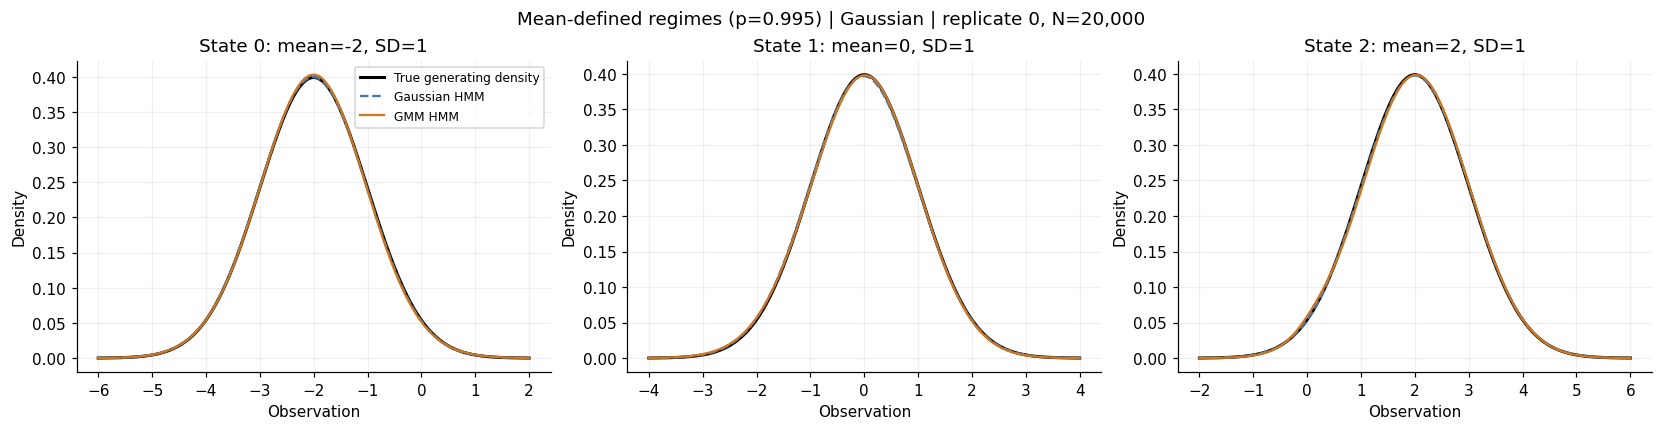

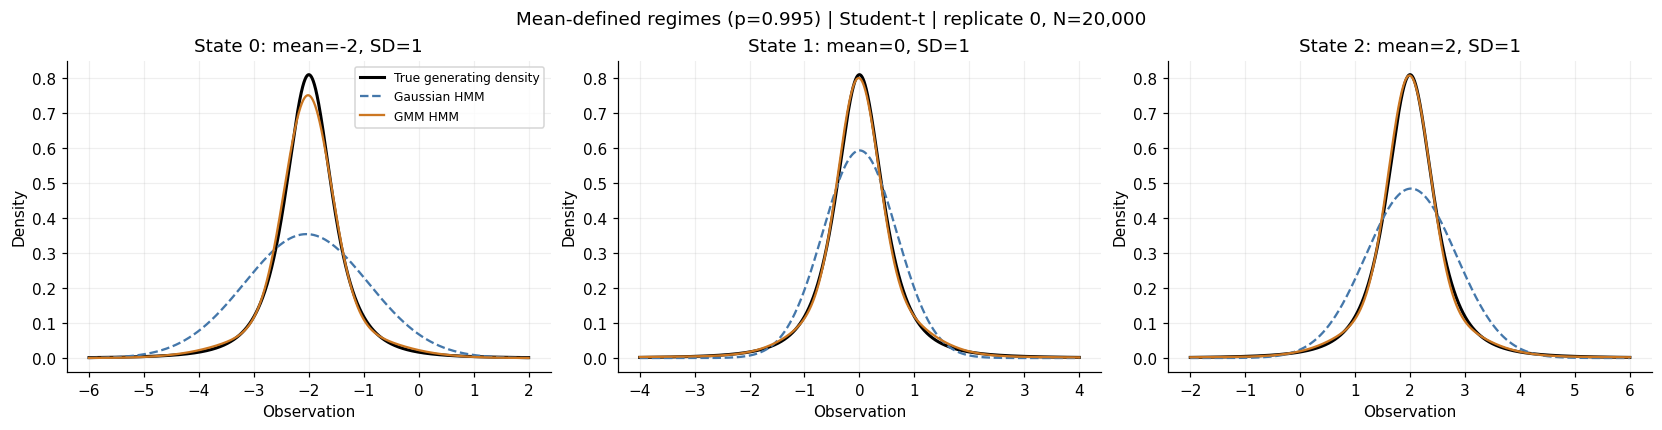

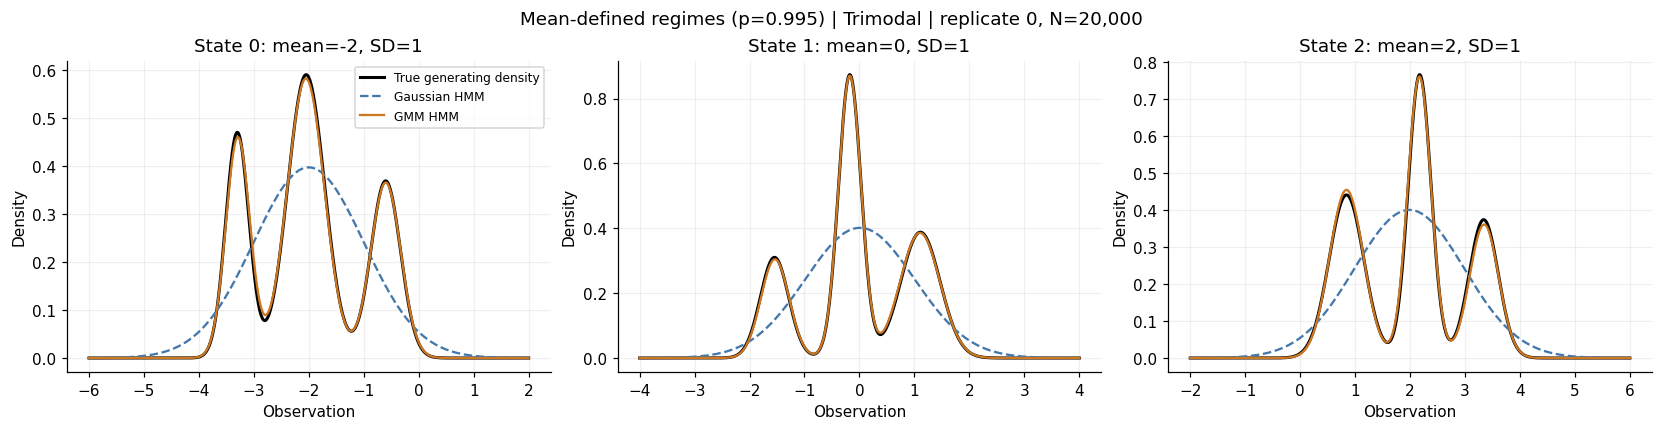

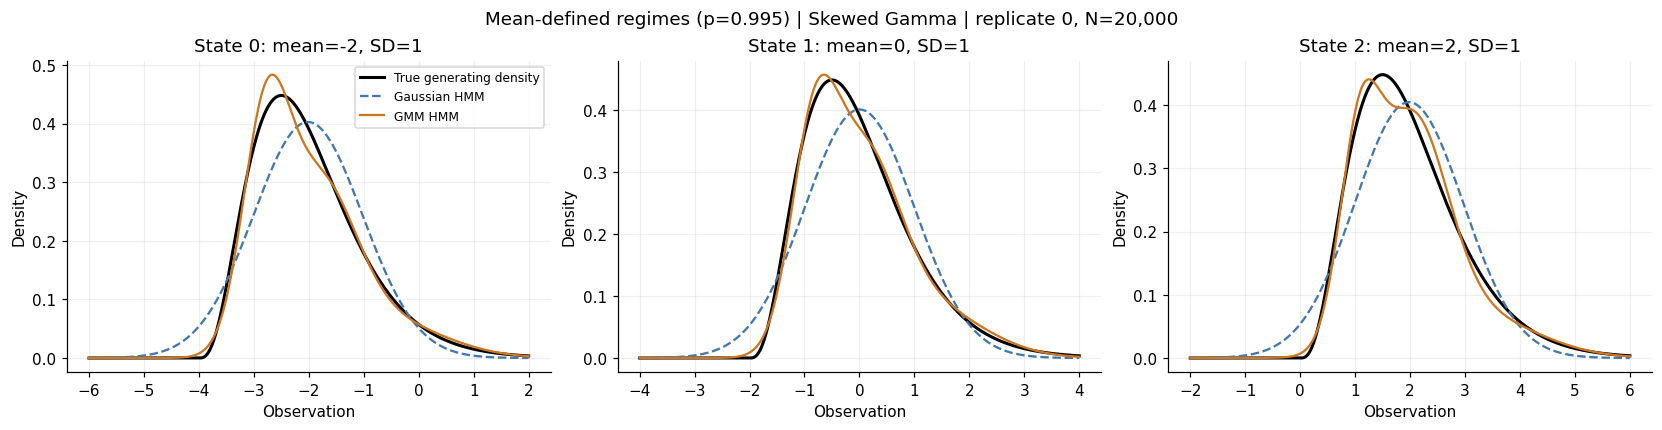

In [35]:
if "run_dir" not in globals():
    raise RuntimeError("Fit and save the mean experiment or set run_dir first")
plot_saved_emission_overlays(
    run_dir, "Mean-defined regimes (p=0.995)", "mean_p995"
)


### Volatility-defined regimes: self-transition probability 0.90

Source fits: /Users/leoyang/Desktop/School/CSCD94/data/synthetic/volatility_markov_experiments/20261025T103033Z-48jhkzmt
True means: [0. 0. 0.]; true standard deviations: [1. 2. 4.]


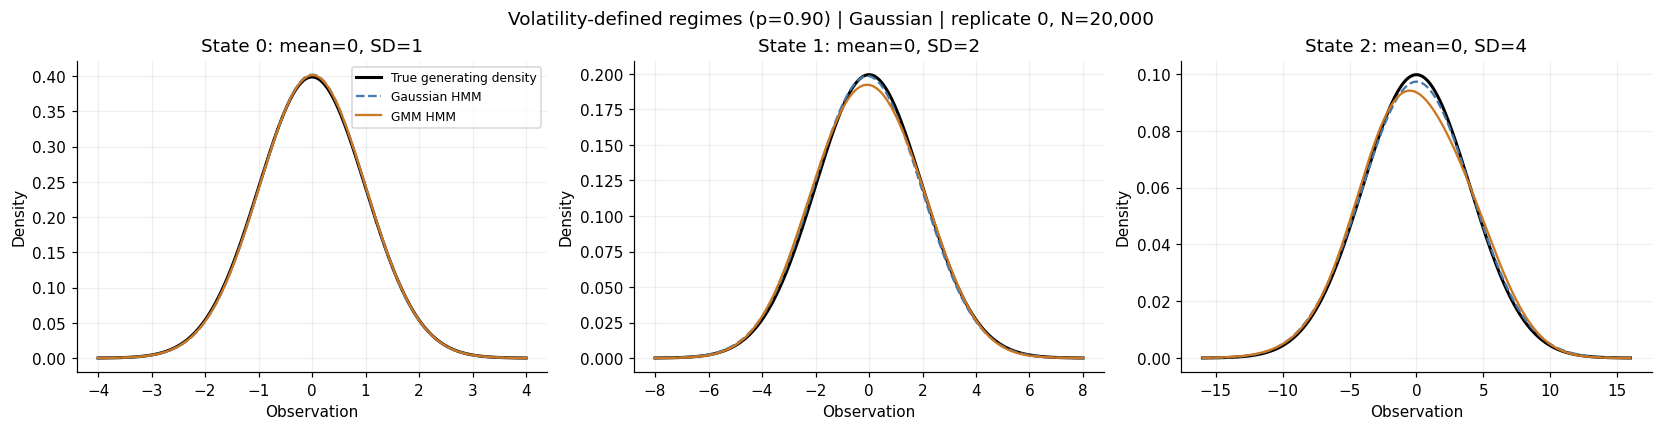

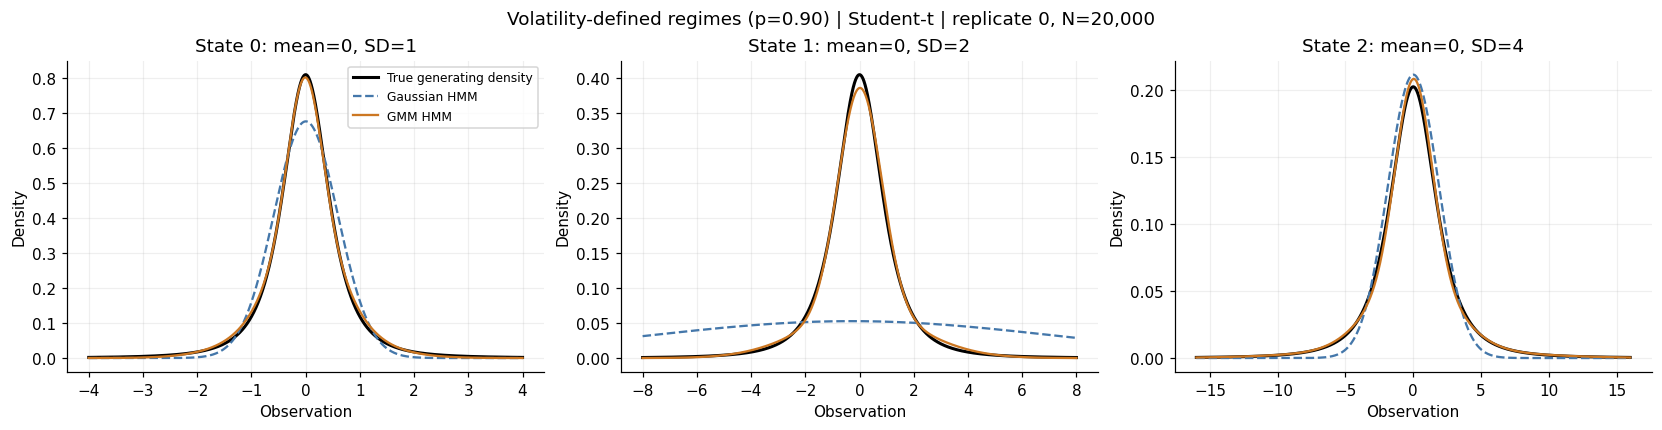

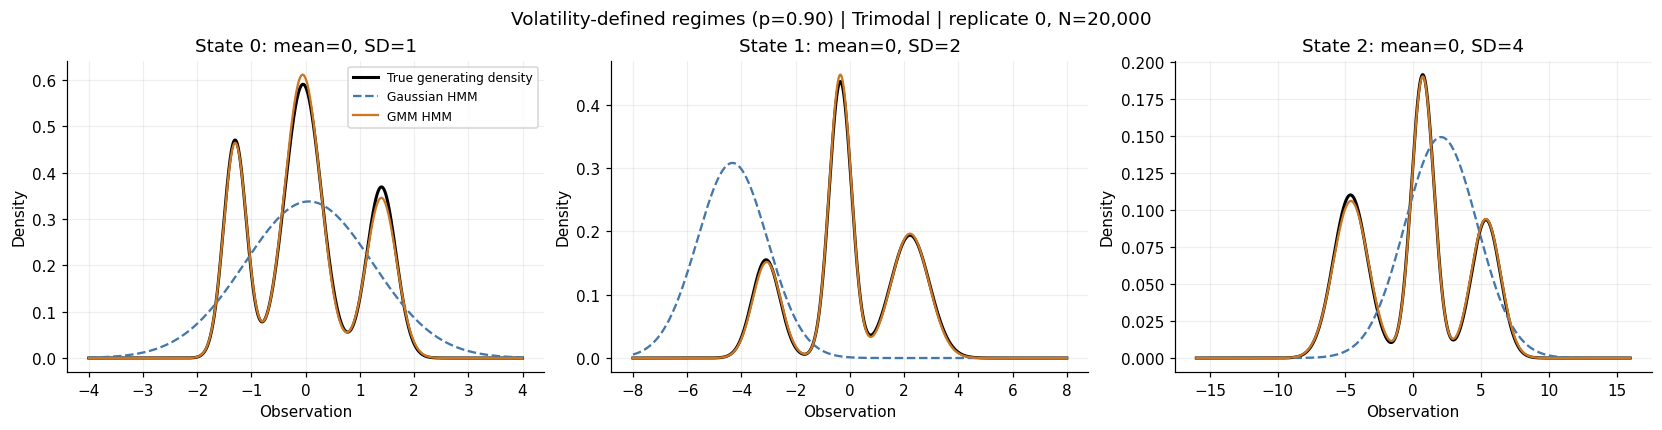

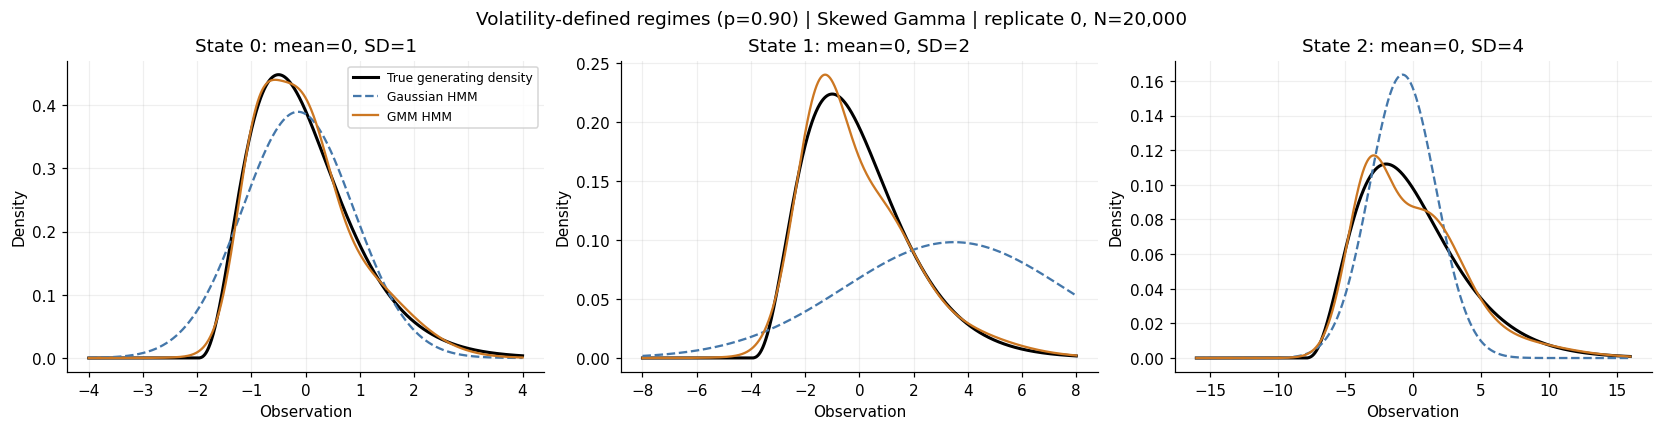

In [36]:
if "vp90_run_dir" not in globals():
    raise RuntimeError(
        "Fit and save the volatility experiment or set vp90_run_dir first"
    )
plot_saved_emission_overlays(
    vp90_run_dir, "Volatility-defined regimes (p=0.90)", "volatility_p90"
)
